# Khai phá quỹ đạo taxi Porto — thực nghiệm offline

Notebook tự chứa cho CS313: GPS → quỹ đạo liên tục → HMM/FMM map matching → quan sát
đi qua đường → thống kê lịch sử → giảm tốc có điều kiện độ phủ → đánh giá ETA.
Markdown tiếng Việt, hàm/biến tiếng Anh. Không có web, API hay demo định tuyến.

**Tài liệu đã đọc trong workspace:** `Trajectory Data Mining An Overview.pdf`
(Yu Zheng, 2015, 41 trang) và `Trajectory_Data_Mining_Porto.pdf` (12 trang,
14/10/2026). Overview §3.1, §3.4–3.5 làm cơ sở lọc nhiễu, phân đoạn và matching
theo chuỗi; §5 nhắc bất định giữa các mẫu; §6.4, §8.2, §9.1 hỗ trợ phân biệt mẫu
lịch sử, sự kiện và biểu diễn mạng đường. Không triển khai toàn bộ thuật toán trong survey.

| Thành phần PDF Porto | Quyết định triển khai và lý do |
|---|---|
| Tiền xử lý, mạng OSM có hướng, matching, ratio, cụm topology | Giữ nguyên khung |
| Timestamp 15 giây/điểm | Tính từ chỉ số **gốc trước lọc**; tách mọi khoảng gián đoạn |
| Tốc độ = chiều dài / thời gian | Dùng **phần cạnh thực đi**; bảo toàn thời gian từng khoảng GPS |
| Chia train/test | Thêm validation, loại chuyến cắt ranh giới theo thời gian đầy đủ |
| 168 giờ/tuần | Chọn nhóm ngày và độ rộng giờ trên validation; có fallback và support |
| Nội suy từng cạnh ngắn | Nội suy theo khoảng cách, không dùng tốc độ tham chiếu; mặc định gộp corridor |
| fastmm/FMM | Ưu tiên fastmm có API phù hợp; HMM Leuven là fallback tường minh nếu không cài được |
| Đánh giá | B0/B1/M1/M2, coverage, độ nhạy, split taxi; không có nhãn ùn tắc độc lập |
| Routing, Streamlit, A/B, lan truyền sự kiện | Hoãn đến demo; chỉ xuất bảng offline có thể tái sử dụng |

Khi chưa có dữ liệu, notebook chạy kiểm tra kỹ thuật rồi ghi `blocked` cho các bước phụ thuộc.
Dữ liệu hình học nhỏ trong kiểm thử là **fixture kiểm thử**, không phải thực nghiệm Porto.
`smoke_test` chỉ kiểm tra kỹ thuật, không đủ để kết luận về giao thông.

## 1. Cấu hình tập trung

Mặc định lấy mẫu theo ngày trong 8 tuần, khoảng 300 chuyến cho smoke test hoặc 20.000
cho experiment. Đặt `data_path` tới `train.csv` hay ZIP chứa `train.csv` đã tải từ Kaggle.
Các mốc có múi giờ Lisbon và khoảng thời gian nửa mở `[start, end)`.
Chuyến có thời điểm cuối chạm/vượt ranh giới bị loại, không cắt rồi đưa sang hai tập.

In [1]:
from pathlib import Path
import os

CFG = {
    "mode": "smoke_test",                   # smoke_test | experiment
    "root": str(Path.cwd()),
    "data_path": "data/train.csv",          # CSV hoặc .zip; không đọc competition test.csv
    "zip_member": None,                     # tự chọn duy nhất file tên train.csv
    "cache_dir": "cache", "output_dir": "outputs",
    "seed": 313,
    "study_start": "2013-07-01T00:00:00+01:00",
    "train_end": "2013-08-05T00:00:00+01:00",
    "validation_end": "2013-08-19T00:00:00+01:00",
    "study_end": "2013-08-26T00:00:00+01:00",
    "bbox": [-8.68, 41.13, -8.57, 41.19],  # west, south, east, north
    "graph_buffer_m": 1200, "metric_crs": "EPSG:32629",
    "max_trips": {"smoke_test": 300, "experiment": 20000},
    "chunk_size": 20000, "matching_batch_size": 50,
    "min_points": 4, "max_points_per_subtrajectory": 300,
    "gps_interval_s": 15, "max_raw_speed_kmh": 150,
    "matcher": "auto",                      # auto | fastmm | leuven
    "allow_leuven_fallback": True,
    "candidate_radius_m": 60, "gps_error_m": 25,
    "max_candidates": 8, "ubodt_delta_m": 1200,
    "hmm_lattice_width": 12, "microedge_max_m": 60,
    "max_match_error_m": 45, "max_mean_match_error_m": 30,
    "min_matched_point_ratio": 0.7,
    "min_retained_interval_ratio": 0.6,
    "max_matched_speed_kmh": 140,
    "max_detour_ratio": 5.0, "detour_floor_m": 40,
    "backward_jitter_m": 5,
    "analysis_unit": "corridor",             # corridor | edge
    "min_unit_observed_distance_m": 15,
    "hour_width_candidates": [1, 2, 4],
    "day_group_candidates": ["weekday_weekend", "weekday"],
    "hour_width": 2,
    "min_trips": 5, "min_taxis": 3, "min_days": 3,
    "support_candidates": [3, 5, 10],
    "slowdown_thresholds": [0.3, 0.4, 0.5],
    "default_slowdown_threshold": 0.4,
    "reference_quantile": 0.85,
    "min_reference_speed_kmh": 3.0, "max_profile_speed_kmh": 120,
    "min_recurrent_frequency": 0.5,
    "min_cluster_edges": 2, "min_cluster_length_m": 100,
    "min_eta_duration_s": 30, "eta_sufficient_fraction": 0.8,
    "run_m2": True,
    "m2_max_train_rows": 150000,
    "m2_candidates": [
        {"max_iter": 100, "max_leaf_nodes": 15, "l2_regularization": 2.0},
        {"max_iter": 160, "max_leaf_nodes": 31, "l2_regularization": 5.0},
    ],
    "cpu_threads": max(1, min(4, (os.cpu_count() or 2) - 1)),
    "force_rematch": False, "force_preprocess": False,
    "allow_graph_download": True, "graph_timeout_s": 90,
    "run_technical_tests": True, "qa_plot_trips": 24,
}
for thread_variable in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"]:
    os.environ[thread_variable] = str(CFG["cpu_threads"])

## 2. Môi trường, cài đặt và nhật ký

Dùng Python 3.11/3.12 nếu muốn wheel fastmm 0.3.2. Trong môi trường tạo notebook
(Python 3.13 Windows), `pip install --only-binary=:all: fastmm` đã trả về không có
distribution phù hợp; vì vậy HMM Leuven được kiểm thử làm fallback. Không gọi
nearest-edge thay cho matching. Mỗi backend có hợp đồng đầu ra riêng và kiểm tra API.

Chạy cell sau bằng cách bỏ dấu `#` ở đầu lệnh nếu thiếu package, rồi restart kernel.
`fastmm` là tùy chọn; không cài package tên `fmm` không rõ nguồn gốc từ PyPI.

In [2]:
# %pip install "numpy>=1.26" "pandas>=2.2" "pyarrow>=15" "networkx>=3" "shapely>=2.1" "pyproj>=3.6" "geopandas>=1" "osmnx>=2,<3" "matplotlib>=3.9" "scikit-learn>=1.5" psutil joblib threadpoolctl leuvenmapmatching rtree tzdata
# %pip install --only-binary=:all: "fastmm==0.3.2"

In [3]:
import sys, json, time, hashlib, sqlite3, zipfile, contextlib, importlib, importlib.metadata
from collections import Counter, defaultdict
from datetime import datetime, timezone

REQUIRED = {
    "numpy": "numpy", "pandas": "pandas", "pyarrow": "pyarrow", "networkx": "networkx",
    "shapely": "shapely", "pyproj": "pyproj", "geopandas": "geopandas", "osmnx": "osmnx",
    "matplotlib": "matplotlib", "sklearn": "scikit-learn", "psutil": "psutil",
    "joblib": "joblib", "threadpoolctl": "threadpoolctl",
}
VERSIONS, MISSING = {}, []
for module_name, distribution in REQUIRED.items():
    if importlib.util.find_spec(module_name) is None:
        MISSING.append(distribution)
    else:
        VERSIONS[distribution] = importlib.metadata.version(distribution)
for optional in ["fastmm", "leuvenmapmatching", "rtree", "tzdata"]:
    try:
        VERSIONS[optional] = importlib.metadata.version(optional)
    except importlib.metadata.PackageNotFoundError:
        VERSIONS[optional] = "not installed"
if MISSING:
    raise RuntimeError("Thiếu package: " + ", ".join(MISSING) + ". Cài ở cell 2 rồi restart kernel.")

import numpy as np
import pandas as pd
import networkx as nx
import geopandas as gpd
import osmnx as ox
import matplotlib.pyplot as plt
import psutil, joblib
from pyproj import Transformer
from shapely.geometry import Point, LineString, box, mapping, MultiLineString
from shapely import transform as transform_coordinates
from shapely.ops import substring
from threadpoolctl import threadpool_limits
from IPython.display import display, Markdown

ROOT = Path(CFG["root"]).resolve()
CACHE = ROOT / CFG["cache_dir"]
OUTPUT = ROOT / CFG["output_dir"]
for folder in [CACHE, OUTPUT, ROOT / "data"]:
    folder.mkdir(parents=True, exist_ok=True)
np.random.seed(CFG["seed"])
PIPELINE_REVISION = "porto-offline-v1.0"

def stable_hash(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, default=str, ensure_ascii=False).encode()).hexdigest()

def file_hash(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(8 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_suffix(path.suffix + ".tmp")
    temp.write_text(json.dumps(value, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
    temp.replace(path)

def write_table(frame, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_suffix(".tmp.parquet")
    frame.to_parquet(temp, index=False)
    temp.replace(path)

def utc(value):
    value = pd.Timestamp(value)
    if value.tzinfo is None:
        raise ValueError("Mốc thời gian phải có timezone.")
    return value.tz_convert("UTC")

BOUNDS = [utc(CFG[k]) for k in ["study_start", "train_end", "validation_end", "study_end"]]
assert BOUNDS == sorted(set(BOUNDS)) and len(BOUNDS) == 4
assert CFG["mode"] in CFG["max_trips"]
assert all(24 % w == 0 for w in CFG["hour_width_candidates"])
assert CFG["analysis_unit"] in ["edge", "corridor"]
assert 0 < CFG["min_matched_point_ratio"] <= 1

source_path = ROOT / "porto_trajectory_mining.ipynb"
if source_path.exists():
    nb_source = json.loads(source_path.read_text(encoding="utf-8"))
    CODE_HASH = stable_hash([c["source"] for c in nb_source["cells"] if c["cell_type"] == "code"
                            and "configuration" not in c.get("metadata",{}).get("tags",[])])
else:
    CODE_HASH = stable_hash(PIPELINE_REVISION)
CONFIG_KEY = stable_hash({"config": {k:v for k,v in CFG.items() if not k.startswith("force_")},
                          "code": CODE_HASH, "versions": VERSIONS})[:16]
# Mỗi lần chạy có output riêng: không trộn bảng cũ khi input đổi hoặc lần chạy mới bị chặn.
RUN_KEY = CONFIG_KEY+"_"+datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
RUN = OUTPUT / RUN_KEY
RUN.mkdir(exist_ok=True)
FIGURES = RUN / "figures"
FIGURES.mkdir(exist_ok=True)
RUNTIME, STAGES = [], {}

def record_stage(name, status, detail):
    STAGES[name] = {"status": status, "detail": str(detail)}
    print(f"[{name}] {status}: {detail}")
    write_json(RUN / "stage_status.json", STAGES)

@contextlib.contextmanager
def timed(name):
    started = time.perf_counter()
    process = psutil.Process()
    memory_before = process.memory_info().rss / 2**20
    try:
        yield
    finally:
        entry = {"stage": name, "seconds": time.perf_counter()-started,
                 "rss_before_mb": memory_before, "rss_after_mb": process.memory_info().rss / 2**20}
        RUNTIME.append(entry)
        write_json(RUN / "runtime.json", RUNTIME)
        print(f"{name}: {entry['seconds']:.2f}s; RSS {entry['rss_after_mb']:.1f} MiB (không phải peak)")

def save_figure(name):
    plt.tight_layout()
    plt.savefig(FIGURES / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

write_json(RUN / "config.json", CFG)
write_json(RUN / "environment.json", {"python": sys.version, "packages": VERSIONS,
           "code_hash": CODE_HASH, "run_key": RUN_KEY, "started_utc": datetime.now(timezone.utc)})
display(pd.Series(VERSIONS, name="version").to_frame())
print("Output:", RUN)

,version
numpy,2.1.3
pandas,2.3.2
pyarrow,23.0.1
networkx,3.5
shapely,2.2.0
pyproj,3.8.0
geopandas,1.2.0
osmnx,2.1.1
matplotlib,3.10.0
scikit-learn,1.7.2


Output: D:\Học tập\Tài liệu\1_2026-2027\CS313\Tracejoy_DataMining\outputs\bdd8bc9d5a3d7c4c_20261021T142049385930Z


## 3. Đọc CSV/ZIP và lấy mẫu phân tầng ngày

Hai lượt đọc chunk: lượt 1 chỉ metadata, lưu SQLite trên đĩa, loại TRIP_ID trùng,
MISSING_DATA, timestamp sai và ngoài kỳ; lượt 2 chỉ parse GPS của các chuyến được chọn.
Priority SHA256(seed, TRIP_ID) trong từng ngày bảo đảm tái lập và không chọn `head(N)`.
Phân bổ quota gần tỷ lệ số chuyến/ngày, có ít nhất một chuyến/ngày khi ngân sách cho phép;
đây là mẫu phân tầng, không tuyên bố mẫu taxi đại diện toàn bộ giao thông.
Báo cáo GPS trước/sau lọc chỉ áp dụng **mẫu được chọn**, không phải toàn bộ CSV.
ID được giữ dưới dạng chuỗi để tránh mất độ chính xác. Không dùng DAYTYPE.

In [4]:
@contextlib.contextmanager
def csv_stream(path, member=None):
    path = Path(path)
    if path.suffix.lower() == ".zip":
        with zipfile.ZipFile(path) as archive:
            candidates = [name for name in archive.namelist() if Path(name).name.lower() == "train.csv"]
            if member is None:
                if len(candidates) != 1:
                    raise ValueError("ZIP cần đúng một train.csv; đặt CFG['zip_member'] nếu cần. Không dùng test.csv.")
                member = candidates[0]
            if Path(member).name.lower() != "train.csv":
                raise ValueError("Chỉ sử dụng train.csv đầy đủ của cuộc thi.")
            with archive.open(member) as handle:
                yield handle
    else:
        if path.name.lower() == "test.csv":
            raise ValueError("Không dùng test.csv quỹ đạo dở dang.")
        with path.open("rb") as handle:
            yield handle

def assign_split(start, end):
    start, end = utc(start), utc(end)
    for label, left, right in zip(["train", "validation", "test"], BOUNDS[:-1], BOUNDS[1:]):
        if start >= left and end < right:
            return label
    return "boundary_or_outside"

def daily_quotas(counts, budget, seed):
    counts = counts.sort_index().astype(int)
    budget = min(int(budget), int(counts.sum()))
    quota = pd.Series(0, index=counts.index, dtype=int)
    if budget < len(counts):
        chosen = sorted(counts.index, key=lambda day: stable_hash([seed, day]))[:budget]
        quota.loc[chosen] = 1
        return quota
    quota[:] = 1
    remaining = budget - len(counts)
    capacity = counts - quota
    if remaining:
        ideal = remaining * capacity / max(1, capacity.sum())
        extra = np.floor(ideal).astype(int)
        quota += extra
        for day in (ideal-extra).sort_values(ascending=False, kind="stable").index[:budget-int(quota.sum())]:
            quota.loc[day] += 1
    return quota

def select_metadata(path, data_key):
    folder = CACHE / "selection" / data_key
    folder.mkdir(parents=True, exist_ok=True)
    selected_path, report_path = folder / "selected.parquet", folder / "report.json"
    if selected_path.exists() and report_path.exists() and not CFG["force_preprocess"]:
        return pd.read_parquet(selected_path), json.loads(report_path.read_text(encoding="utf-8"))
    database = folder / "metadata.sqlite"
    with sqlite3.connect(database) as connection:
        connection.execute("DROP TABLE IF EXISTS trips")
        connection.execute("CREATE TABLE trips (trip_id TEXT PRIMARY KEY, taxi_id TEXT, timestamp INTEGER, day TEXT, priority TEXT, source_row INTEGER)")
        counts, offset = Counter(), 0
        with csv_stream(path, CFG["zip_member"]) as handle:
            chunks = pd.read_csv(handle, usecols=["TRIP_ID","TAXI_ID","TIMESTAMP","MISSING_DATA"],
                                 dtype="string", chunksize=CFG["chunk_size"])
            for chunk in chunks:
                counts["raw_rows"] += len(chunk)
                times = pd.to_datetime(pd.to_numeric(chunk.TIMESTAMP, errors="coerce"), unit="s", utc=True, errors="coerce")
                missing = chunk.MISSING_DATA.str.lower().str.strip()
                valid_missing = missing.isin(["false", "0", "true", "1"])
                counts["missing_data_true"] += int(missing.isin(["true", "1"]).sum())
                counts["missing_flag_invalid"] += int((~valid_missing).sum())
                counts["invalid_timestamp"] += int(times.isna().sum())
                mask = (missing.isin(["false", "0"]) & times.ge(BOUNDS[0]) & times.lt(BOUNDS[-1])
                        & chunk.TRIP_ID.notna() & chunk.TAXI_ID.notna())
                records = []
                for position in np.flatnonzero(mask.to_numpy(dtype=bool, na_value=False)):
                    row = chunk.iloc[position]
                    timestamp = int(times.iloc[position].timestamp())
                    day = str(times.iloc[position].tz_convert("Europe/Lisbon").date())
                    records.append((str(row.TRIP_ID), str(row.TAXI_ID), timestamp, day,
                                    stable_hash([CFG["seed"], str(row.TRIP_ID)]), offset+int(position)))
                previous = connection.total_changes
                connection.executemany("INSERT OR IGNORE INTO trips VALUES (?,?,?,?,?,?)", records)
                counts["duplicates_eligible"] += len(records) - (connection.total_changes-previous)
                offset += len(chunk)
                connection.commit()
        day_counts = pd.read_sql_query("SELECT day, COUNT(*) n FROM trips GROUP BY day ORDER BY day", connection)
        if day_counts.empty:
            raise ValueError("Không có chuyến hợp lệ trong study_start/study_end. Kiểm tra khoảng ngày.")
        quota = daily_quotas(day_counts.set_index("day").n, CFG["max_trips"][CFG["mode"]], CFG["seed"])
        connection.execute("CREATE INDEX IF NOT EXISTS day_priority ON trips(day,priority)")
        selected = pd.concat([pd.read_sql_query("SELECT trip_id,taxi_id,timestamp,day,source_row FROM trips WHERE day=? ORDER BY priority LIMIT ?", connection,
                                params=(day, int(number))) for day, number in quota.items() if number], ignore_index=True)
        report = dict(counts)
        report.update({"eligible_unique_trips": int(day_counts.n.sum()), "eligible_days": len(day_counts),
                       "eligible_taxis": int(connection.execute("SELECT COUNT(DISTINCT taxi_id) FROM trips").fetchone()[0]),
                       "sampled_trips": len(selected), "sampled_days": selected.day.nunique(),
                       "before_gps_scope": "selected sample only"})
        write_table(day_counts.assign(quota=day_counts.day.map(quota)), folder / "sampling_by_day.parquet")
    write_table(selected.sort_values("source_row"), selected_path)
    write_json(report_path, report)
    return selected, report

PROJECT = Transformer.from_crs("EPSG:4326", CFG["metric_crs"], always_xy=True)
UNPROJECT = Transformer.from_crs(CFG["metric_crs"], "EPSG:4326", always_xy=True)
STUDY_POLYGON = transform_coordinates(box(*CFG["bbox"]),PROJECT.transform,interleaved=False)

def clean_polyline(polyline, timestamp):
    """Tính index/time trước mọi phép lọc; không nối qua điểm lỗi hoặc ngoài vùng."""
    try:
        coordinates = json.loads(polyline)
    except (ValueError, TypeError):
        return [], {"reason": "invalid_json", "raw_points": 0}
    if not isinstance(coordinates, list):
        return [], {"reason": "invalid_polyline", "raw_points": 0}
    raw_count = len(coordinates)
    valid = []
    invalid = outside = 0
    west, south, east, north = CFG["bbox"]
    for original_index, pair in enumerate(coordinates):
        try:
            if len(pair) != 2:
                raise ValueError("coordinate shape")
            lon, lat = map(float, pair)
            if not np.isfinite([lon,lat]).all() or not (-180<=lon<=180 and -90<=lat<=90):
                raise ValueError("coordinate range")
        except (TypeError, ValueError, OverflowError):
            invalid += 1
            continue
        if not (west<=lon<=east and south<=lat<=north):
            outside += 1
            continue
        x, y = PROJECT.transform(lon, lat)
        valid.append({"original_index": original_index, "timestamp": int(timestamp)+CFG["gps_interval_s"]*original_index,
                      "lon": lon, "lat": lat, "x": x, "y": y})
    parts, part = [], []
    jumps = 0
    for point in valid:
        if part:
            previous = part[-1]
            dt = point["timestamp"]-previous["timestamp"]
            speed = 3.6*np.hypot(point["x"]-previous["x"],point["y"]-previous["y"])/dt
            discontinuity = point["original_index"] != previous["original_index"]+1
            if discontinuity or speed > CFG["max_raw_speed_kmh"]:
                jumps += int(speed > CFG["max_raw_speed_kmh"])
                if len(part)>=CFG["min_points"]:
                    parts.append(part)
                part = []
        part.append(point)
        if len(part) >= CFG["max_points_per_subtrajectory"]:
            parts.append(part)
            part = [point]  # chung đúng một endpoint; không nhân đôi khoảng GPS
    if len(part)>=CFG["min_points"]:
        parts.append(part)
    return parts, {"reason": "retained" if parts else "empty_short_or_discontinuous", "raw_points": raw_count,
                   "valid_in_region_points": len(valid), "invalid_points": invalid,
                   "outside_points": outside, "jump_boundaries": jumps,
                   "kept_points": len({p["original_index"] for part in parts for p in part}),
                   "original_end_timestamp": int(timestamp)+CFG["gps_interval_s"]*max(0,raw_count-1)}

def prepare_sample(path, selected, data_key):
    folder = CACHE / "selection" / data_key
    trips_path, parts_path = folder / "trip_audit.parquet", folder / "subtrajectories.jsonl"
    if trips_path.exists() and parts_path.exists() and not CFG["force_preprocess"]:
        return pd.read_parquet(trips_path), parts_path
    wanted = set(selected.source_row.astype(int))
    audit, offset = [], 0
    temp = parts_path.with_suffix(".tmp")
    with temp.open("w", encoding="utf-8") as output, csv_stream(path, CFG["zip_member"]) as handle:
        chunks = pd.read_csv(handle, usecols=["TRIP_ID","TAXI_ID","TIMESTAMP","POLYLINE","MISSING_DATA"],
                             dtype="string", chunksize=CFG["chunk_size"])
        for chunk in chunks:
            positions = [i for i in range(len(chunk)) if offset+i in wanted]
            for position in positions:
                row = chunk.iloc[position]
                timestamp = int(row.TIMESTAMP)
                parts, report = clean_polyline(row.POLYLINE, timestamp)
                end = pd.Timestamp(report.get("original_end_timestamp",timestamp),unit="s",tz="UTC")
                split = assign_split(pd.Timestamp(timestamp,unit="s",tz="UTC"), end)
                if split == "boundary_or_outside":
                    parts = []
                    report["reason"] = split
                    report["kept_points"] = 0
                item = {"trip_id": str(row.TRIP_ID), "taxi_id": str(row.TAXI_ID),
                        "trip_start": pd.Timestamp(timestamp,unit="s",tz="UTC"), "trip_end": end,
                        "day": str(pd.Timestamp(timestamp,unit="s",tz="UTC").tz_convert("Europe/Lisbon").date()),
                        "split": split, "n_subtrajectories": len(parts), **report}
                audit.append(item)
                for index, points in enumerate(parts):
                    sub = {"trip_id": item["trip_id"], "taxi_id": item["taxi_id"], "split": split,
                           "subtrajectory_id": f"{item['trip_id']}:{index}", "points": points}
                    output.write(json.dumps(sub)+"\n")
            offset += len(chunk)
    temp.replace(parts_path)
    frame = pd.DataFrame(audit)
    write_table(frame, trips_path)
    return frame, parts_path

,value
raw_rows,1710670
missing_data_true,10
missing_flag_invalid,0
invalid_timestamp,0
duplicates_eligible,8
eligible_unique_trips,247300
eligible_days,56
eligible_taxis,436
sampled_trips,300
sampled_days,56


,stage,trips,taxis,days,gps_points
0,sample_before_gps_filter,300,204,56,13535
1,after_gps_and_boundary_filter,292,199,56,11597


,trips
reason,
empty_short_or_discontinuous,8
retained,292


,raw_points,kept_points
count,300.000000,300.000000
mean,45.116667,38.656667
std,30.305740,22.939913
min,0.000000,0.000000
10%,19.000000,16.000000
50%,38.000000,35.000000
90%,78.100000,62.100000
99%,143.160000,136.030000
max,235.000000,153.000000


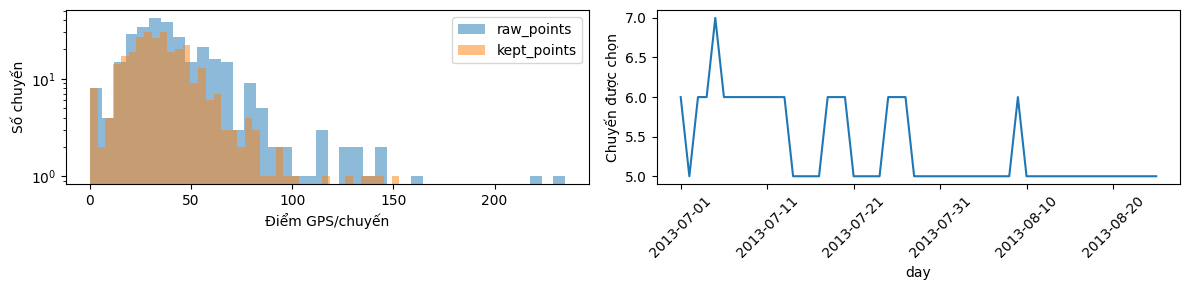

[data] complete: 300 chuyến trong mẫu; xem trip_audit.
ingestion_and_cleaning: 63.97s; RSS 303.6 MiB (không phải peak)


In [5]:
DATA_PATH = ROOT / CFG["data_path"]
SELECTED = TRIP_AUDIT = None
PARTS_PATH = None
DATA_KEY = None
if not DATA_PATH.exists():
    alternatives = [p for p in [ROOT/"train.csv", ROOT/"train.csv.zip", ROOT/"data/train.csv.zip",
                    ROOT/"data/pkdd-15-predict-taxi-service-trajectory-i.zip"] if p.exists()]
    if len(alternatives)==1:
        DATA_PATH = alternatives[0]
if DATA_PATH.exists():
    with timed("ingestion_and_cleaning"):
        DATA_SHA = file_hash(DATA_PATH)
        DATA_KEY = stable_hash([DATA_SHA, {k:v for k,v in CFG.items() if not k.startswith("force_")}, CODE_HASH, VERSIONS])[:20]
        SELECTED, INGEST_REPORT = select_metadata(DATA_PATH, DATA_KEY)
        TRIP_AUDIT, PARTS_PATH = prepare_sample(DATA_PATH, SELECTED, DATA_KEY)
        write_json(RUN/"data_source.json", {"path": str(DATA_PATH), "sha256": DATA_SHA, "data_key": DATA_KEY,
                   "dataset": "Kaggle ECML/PKDD 2015 trajectory prediction I; train.csv"})
        write_json(RUN/"ingestion_report.json", INGEST_REPORT)
        write_table(TRIP_AUDIT, RUN/"trip_audit.parquet")
        display(pd.Series(INGEST_REPORT).to_frame("value"))
        summary = []
        for stage, frame in [("sample_before_gps_filter",TRIP_AUDIT),
                             ("after_gps_and_boundary_filter",TRIP_AUDIT[TRIP_AUDIT.n_subtrajectories>0])]:
            column = "raw_points" if stage.startswith("sample") else "kept_points"
            summary.append({"stage":stage,"trips":len(frame),"taxis":frame.taxi_id.nunique(),
                            "days":frame.day.nunique(),"gps_points":int(frame[column].sum())})
        display(pd.DataFrame(summary))
        write_table(pd.DataFrame(summary), RUN/"filter_counts.parquet")
        write_table(TRIP_AUDIT.groupby(["split","reason"]).size().rename("trips").reset_index(), RUN/"split_summary.parquet")
        display(TRIP_AUDIT.groupby("reason").size().to_frame("trips"))
        display(TRIP_AUDIT[["raw_points","kept_points"]].describe(percentiles=[.1,.5,.9,.99]))
        fig, axes = plt.subplots(1,2,figsize=(12,3))
        for column in ["raw_points","kept_points"]:
            axes[0].hist(TRIP_AUDIT[column],bins=40,alpha=.5,label=column)
        axes[0].set(xlabel="Điểm GPS/chuyến",ylabel="Số chuyến",yscale="log"); axes[0].legend()
        TRIP_AUDIT.groupby("day").size().plot(ax=axes[1],rot=45,ylabel="Chuyến được chọn")
        save_figure("data_distribution")
        record_stage("data", "complete", f"{len(TRIP_AUDIT)} chuyến trong mẫu; xem trip_audit.")
else:
    record_stage("data", "blocked", f"Thiếu {DATA_PATH}; đặt train.csv hoặc ZIP và sửa CFG['data_path'].")

## 4. Mạng đường có hướng, CRS mét và cache graph

Graph lái xe có buffer được lưu GraphML, metadata và GeoParquet. `edge_id = u:v:key`
ổn định trong graph snapshot; mọi output mang graph hash. Hình học được định hướng
từ u tới v trước khi đo offset. Độ dài dùng cho matching và partial distance là
chiều dài LineString trong UTM 29N. Không dùng tọa độ độ cho khoảng cách.
OSM hiện tại có thể khác 2013; graph hash/snapshot không làm mất sai lệch lịch sử này.

In [6]:
def scalar_attribute(value, default="unknown"):
    if isinstance(value, (list,tuple,set)):
        return "|".join(sorted(map(str,value)))
    return default if value is None else str(value)

def make_edge_table(graph):
    rows = []
    for u,v,key,data in sorted(graph.edges(keys=True,data=True),key=lambda e: (int(e[0]),int(e[1]),int(e[2]))):
        start = Point(graph.nodes[u]["x"],graph.nodes[u]["y"])
        end = Point(graph.nodes[v]["x"],graph.nodes[v]["y"])
        geometry = data.get("geometry",LineString([start,end]))
        if not isinstance(geometry,LineString) or geometry.length<=0:
            continue
        coordinates = []
        for coordinate in geometry.coords:
            if not coordinates or np.hypot(coordinate[0]-coordinates[-1][0],coordinate[1]-coordinates[-1][1])>1e-6:
                coordinates.append(coordinate)
        if len(coordinates)<2:
            continue
        geometry = LineString(coordinates)
        if Point(geometry.coords[-1]).distance(start) < Point(geometry.coords[0]).distance(start):
            geometry = LineString(list(geometry.coords)[::-1])
        if Point(geometry.coords[0]).distance(start)>2 or Point(geometry.coords[-1]).distance(end)>2:
            raise ValueError(f"Hình học cạnh {u}:{v}:{key} không khớp node endpoints.")
        rows.append({"edge_id": f"{u}:{v}:{key}","u":int(u),"v":int(v),"key":int(key),
                     "length_m":geometry.length,"road_class":scalar_attribute(data.get("highway")),
                     "maxspeed":scalar_attribute(data.get("maxspeed")),
                     "geometry":geometry,"x":geometry.centroid.x,"y":geometry.centroid.y,
                     "in_study":STUDY_POLYGON.covers(geometry)})
    edges = gpd.GeoDataFrame(rows,geometry="geometry",crs=graph.graph["crs"])
    edges["fmm_id"] = np.arange(1,len(edges)+1,dtype=np.int64)
    return edges

def load_road_graph():
    graph_config = {k:CFG[k] for k in ["bbox","graph_buffer_m","metric_crs"]}
    graph_config.update({"network_type":"drive","simplify":True,"osmnx":VERSIONS["osmnx"]})
    folder = CACHE / "graphs" / stable_hash(graph_config)[:16]
    folder.mkdir(parents=True, exist_ok=True)
    graph_path, metadata_path = folder/"porto.graphml",folder/"metadata.json"
    if graph_path.exists() and metadata_path.exists():
        graph = ox.load_graphml(graph_path)
        metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
        if metadata["graph_file_sha256"] != file_hash(graph_path):
            raise RuntimeError("Graph cache bị thay đổi; kiểm tra/xóa snapshot không hợp lệ.")
    else:
        if not CFG["allow_graph_download"]:
            raise RuntimeError("Chưa có road graph cache và allow_graph_download=False.")
        ox.settings.use_cache = True
        ox.settings.cache_folder = str(CACHE/"osmnx_http")
        ox.settings.requests_timeout = CFG["graph_timeout_s"]
        buffered = STUDY_POLYGON.buffer(CFG["graph_buffer_m"])
        query_polygon = transform_coordinates(buffered,UNPROJECT.transform,interleaved=False)
        graph = ox.graph_from_polygon(query_polygon,network_type="drive",simplify=True,retain_all=True,truncate_by_edge=True)
        graph = ox.project_graph(graph,to_crs=CFG["metric_crs"])
        ox.save_graphml(graph,graph_path)
        metadata = {"downloaded_utc":datetime.now(timezone.utc).isoformat(),"config":graph_config,
                    "source":"OpenStreetMap contributors via OSMnx / Overpass", "historical_snapshot":False,
                    "graph_file_sha256":file_hash(graph_path)}
        write_json(metadata_path,metadata)
    edges = make_edge_table(graph)
    graph_hash = stable_hash([[r.edge_id,r.geometry.wkb_hex,r.road_class,r.maxspeed] for r in edges.itertuples()])
    metadata["graph_hash"] = graph_hash
    edges["graph_hash"] = graph_hash
    write_json(metadata_path,metadata)
    edges.to_parquet(folder/"edges.parquet",index=False)
    return graph,edges,graph_hash,folder,metadata

In [7]:
GRAPH = EDGES = GRAPH_HASH = GRAPH_FOLDER = None
with timed("road_graph"):
    try:
        GRAPH, EDGES, GRAPH_HASH, GRAPH_FOLDER, GRAPH_METADATA = load_road_graph()
        write_json(RUN/"graph_metadata.json",{**GRAPH_METADATA,"graph_folder":str(GRAPH_FOLDER)})
        EDGES.to_parquet(RUN/"edges.parquet",index=False)
        display(pd.DataFrame({"nodes":[len(GRAPH)],"edges":[len(EDGES)],
                             "full_edges_in_study":[int(EDGES.in_study.sum())],
                             "weak_components":[nx.number_weakly_connected_components(GRAPH)]}))
        record_stage("graph","complete",f"{len(EDGES)} cạnh; graph_hash={GRAPH_HASH[:16]}")
    except Exception as error:
        record_stage("graph","blocked",f"{type(error).__name__}: {error}")

,nodes,edges,full_edges_in_study,weak_components
0,11241,23732,15043,29


[graph] complete: 23732 cạnh; graph_hash=862367c3d1f7fde1
road_graph: 5.17s; RSS 457.6 MiB (không phải peak)


## 5. Matching theo chuỗi và kiểm định từng khoảng GPS

`fastmm` dùng `Network.add_edge/finalize`, `FastMapMatch(..., SHORTEST)` và
`Trajectory.from_xyt_tuples` theo API chính thức 0.3.2. Tự phân bổ thời gian từ
`segment.p0/p1` và offset của `segment.edges`, không tin mù quáng thời gian nội suy sẵn.
Chỉ giữ các cặp có timestamp đúng hai điểm **liên tiếp** trong đầu vào.

Leuven `DistanceMatcher` dùng graph phẳng có hướng. Mỗi hình học cạnh được tách thành
microedges theo vertices và chiều dài tối đa; node nội bộ riêng cho từng `(u,v,key)`
giữ được cạnh cong và các cạnh song song. Lấy đường từ `lattice_best` gồm các trạng
thái emitting/non-emitting; **không** tìm shortest path thay thế cho đoạn lattice bị đứt.
Kiểm tra các thuộc tính lattice ở runtime; phiên bản không tương thích sẽ bị chặn.
Leuven chậm hơn C++: tăng experiment sau khi quan sát runtime và QA.

Khoảng GPS bị rớt, ngược hướng vượt jitter, mất liên thông, lỗi lớn, tốc độ phi lý,
detour quá lớn hoặc đi qua cạnh ngoài vùng đều tạo khoảng gián đoạn, không được nối lại.
`matcher_returned` và `analysis_accepted` là hai trạng thái khác nhau.
Sai lệch GPS–road là tiêu chí QA, không phải xác suất đúng đường đã hiệu chuẩn.

In [8]:
def collapse_parts(parts):
    combined = []
    for edge_id, start_offset, end_offset in parts:
        if end_offset < start_offset-CFG["backward_jitter_m"]:
            raise ValueError("backward_offset")
        end_offset = max(start_offset,end_offset)
        if combined and combined[-1][0] == edge_id and abs(combined[-1][2]-start_offset)<.01:
            combined[-1] = (edge_id,combined[-1][1],end_offset)
        else:
            combined.append((edge_id,float(start_offset),float(end_offset)))
    return combined

class FastMMAdapter:
    name = "fastmm"
    def __init__(self, edges, cache_dir):
        import fastmm
        required = ["Network","FastMapMatch","Trajectory","TransitionMode","MatchErrorCode"]
        if not all(hasattr(fastmm,item) for item in required):
            raise RuntimeError("fastmm API không tương thích; cần API 0.3.2 trong tài liệu tham khảo.")
        self.library = fastmm
        self.id_map = dict(zip(edges.fmm_id.astype(int),edges.edge_id))
        self.network = fastmm.Network()
        for row in edges.itertuples():
            self.network.add_edge(int(row.fmm_id),source=int(row.u),target=int(row.v),
                                  geom=[list(pair) for pair in row.geometry.coords])
        self.network.finalize()
        self.matcher = fastmm.FastMapMatch(self.network,fastmm.TransitionMode.SHORTEST,
                       max_distance_between_candidates=CFG["ubodt_delta_m"],cache_dir=cache_dir)
        if not hasattr(fastmm.Trajectory,"from_xyt_tuples"):
            raise RuntimeError("Thiếu Trajectory.from_xyt_tuples trong phiên bản fastmm này.")

    def match(self, points):
        trajectory = self.library.Trajectory.from_xyt_tuples([(p["x"],p["y"],p["timestamp"]) for p in points])
        result = self.matcher.match(trajectory,max_candidates=CFG["max_candidates"],
                     candidate_search_radius=CFG["candidate_radius_m"],gps_error=CFG["gps_error_m"],reverse_tolerance=0.0)
        if not hasattr(result,"subtrajectories"):
            raise RuntimeError("fastmm result không có subtrajectories.")
        time_to_index = {p["timestamp"]:i for i,p in enumerate(points)}
        intervals, matched_points = [], {}
        for sub in result.subtrajectories:
            if sub.error_code != self.library.MatchErrorCode.SUCCESS:
                continue
            for segment in sub.segments:
                first,last = segment.p0,segment.p1
                i,j = time_to_index.get(round(first.t)), time_to_index.get(round(last.t))
                if i is None or j != i+1:
                    continue
                parts = []
                for edge in segment.edges:
                    if edge.reversed:
                        raise ValueError("fastmm reversed edge không được chấp nhận khi reverse_tolerance=0.")
                    if len(edge.points)<2:
                        continue
                    parts.append((self.id_map[int(edge.edge_id)],float(edge.points[0].edge_offset),float(edge.points[-1].edge_offset)))
                if not parts:
                    continue
                errors = [float(c.perpendicular_distance_to_matched_geometry) for c in [first,last]]
                for index,candidate,edge_id in [(i,first,parts[0][0]),(j,last,parts[-1][0])]:
                    matched_points[index] = {"point_index":index,"edge_id":edge_id,"matched_x":candidate.x,
                                             "matched_y":candidate.y,"error_m":float(candidate.perpendicular_distance_to_matched_geometry)}
                intervals.append({"i":i,"j":j,"parts":collapse_parts(parts),"error_m":max(errors)})
        return intervals,list(matched_points.values())

class LeuvenAdapter:
    name = "leuven_hmm"
    def __init__(self, edges, cache_dir):
        from leuvenmapmatching.map.inmem import InMemMap
        from leuvenmapmatching.matcher.distance import DistanceMatcher
        self.matcher_class = DistanceMatcher
        graph, self.micro = {}, {}
        node_map = {int(value):index for index,value in enumerate(sorted(set(edges.u)|set(edges.v)))}
        next_node = len(node_map)
        for row in edges.itertuples():
            coordinates = list(row.geometry.coords)
            # Ít nhất 2 microedges: phân biệt song song kể cả cạnh thẳng.
            if len(coordinates)==2:
                middle = row.geometry.interpolate(.5,normalized=True)
                coordinates.insert(1,(middle.x,middle.y))
            dense = [coordinates[0]]
            for a,b in zip(coordinates[:-1],coordinates[1:]):
                distance = np.hypot(b[0]-a[0],b[1]-a[1])
                for fraction in np.linspace(0,1,max(1,int(np.ceil(distance/CFG["microedge_max_m"])))+1)[1:]:
                    dense.append((a[0]+fraction*(b[0]-a[0]),a[1]+fraction*(b[1]-a[1])))
            labels = [node_map[int(row.u)]]
            for _ in dense[1:-1]:
                labels.append(next_node)
                next_node += 1
            labels.append(node_map[int(row.v)])
            offset = 0.0
            for index,(a,b) in enumerate(zip(dense[:-1],dense[1:])):
                length = float(np.hypot(b[0]-a[0],b[1]-a[1]))
                if length<1e-8:
                    raise ValueError("Zero length vertex segment trong road geometry.")
                left,right = labels[index],labels[index+1]
                for node,coordinate in [(left,a),(right,b)]:
                    if node not in graph:
                        graph[node] = ((coordinate[1],coordinate[0]),[])
                graph[left][1].append(right)
                self.micro[(left,right)] = {"edge_id":row.edge_id,"start":offset,"length":length,
                                           "line":LineString([a,b])}
                offset += length
        self.map = InMemMap("porto_projected_directed",graph=graph,use_latlon=False,use_rtree=True,index_edges=True)

    def match(self, points):
        matcher = self.matcher_class(self.map,max_dist=CFG["candidate_radius_m"],
                    max_dist_init=CFG["candidate_radius_m"],obs_noise=CFG["gps_error_m"],
                    dist_noise=CFG["gps_error_m"]*2,min_prob_norm=.001,
                    max_lattice_width=CFG["hmm_lattice_width"],non_emitting_states=True,
                    only_edges=True,avoid_goingback=True)
        matcher.match([(p["y"],p["x"]) for p in points],unique=False)
        lattice = matcher.lattice_best or []
        if lattice and not all(hasattr(lattice[0],name) for name in ["obs","obs_ne","edge_m","dist_obs"]):
            raise RuntimeError("Leuven lattice API không tương thích với adapter.")
        emitting = [(position,state) for position,state in enumerate(lattice) if state.obs_ne==0]
        intervals, matched_points = [], []
        for position,state in emitting:
            index = int(state.obs)
            micro = self.micro[(state.edge_m.l1,state.edge_m.l2)]
            raw = Point(points[index]["x"],points[index]["y"])
            snapped = micro["line"].interpolate(micro["line"].project(raw))
            matched_points.append({"point_index":index,"edge_id":micro["edge_id"],
                                   "matched_x":snapped.x,"matched_y":snapped.y,"error_m":snapped.distance(raw)})
        for (left_position,left),(right_position,right) in zip(emitting[:-1],emitting[1:]):
            i,j = int(left.obs),int(right.obs)
            if j!=i+1:
                continue
            sequence = []
            for state in lattice[left_position:right_position+1]:
                key = (state.edge_m.l1,state.edge_m.l2)
                if not sequence or sequence[-1]!=key:
                    sequence.append(key)
            if any(a[1]!=b[0] for a,b in zip(sequence[:-1],sequence[1:])):
                continue
            parts = []
            for position,key in enumerate(sequence):
                micro = self.micro[key]
                begin,end = 0.0,micro["length"]
                if position==0:
                    begin = micro["line"].project(Point(points[i]["x"],points[i]["y"]))
                if position==len(sequence)-1:
                    end = micro["line"].project(Point(points[j]["x"],points[j]["y"]))
                parts.append((micro["edge_id"],micro["start"]+begin,micro["start"]+end))
            try:
                parts = collapse_parts(parts)
            except ValueError:
                continue
            intervals.append({"i":i,"j":j,"parts":parts,"error_m":max(float(left.dist_obs),float(right.dist_obs))})
        return intervals,matched_points

def build_matcher(edges, cache_dir):
    errors = []
    if CFG["matcher"] in ["auto","fastmm"]:
        try:
            return FastMMAdapter(edges,cache_dir)
        except (ImportError,RuntimeError,TypeError,AttributeError) as error:
            errors.append(f"fastmm: {type(error).__name__}: {error}")
            if CFG["matcher"]=="fastmm" or not CFG["allow_leuven_fallback"]:
                raise RuntimeError("; ".join(errors)) from error
    if CFG["matcher"] in ["auto","leuven"]:
        try:
            engine = LeuvenAdapter(edges,cache_dir)
            if errors:
                print("Fallback HMM Leuven được bật:","; ".join(errors))
            return engine
        except ImportError as error:
            raise RuntimeError("Không có matcher khả dụng. Cài fastmm phù hợp hoặc leuvenmapmatching + rtree.") from error
    raise ValueError("CFG['matcher'] phải là auto/fastmm/leuven.")

def interval_pieces(parts, duration_s):
    """Nội suy chỉ theo độ dài; tổng thời gian đúng bằng khoảng GPS."""
    distances = np.array([max(0.0,b-a) for _,a,b in parts])
    if distances.sum()==0:
        if len(parts)!=1:
            raise ValueError("zero_distance_multiple_edges")
        durations = np.array([duration_s],dtype=float)
    else:
        durations = duration_s*distances/distances.sum()
        durations[-1] += duration_s-durations.sum()
    return [(edge,a,b,float(d),float(t)) for (edge,a,b),d,t in zip(parts,distances,durations) if t>1e-10]

def match_subtrajectory(sub, engine, edge_lookup):
    points = sub["points"]
    intervals, snapped = engine.match(points)
    snapped_unique = {int(item["point_index"]):item for item in snapped}
    returned = bool(intervals)
    point_ratio = len(snapped_unique)/len(points)
    mean_error = float(np.mean([p["error_m"] for p in snapped])) if snapped else np.nan
    audits, accepted = [], []
    seen = set()
    for interval in intervals:
        i,j,parts = interval["i"],interval["j"],interval["parts"]
        if (i,j) in seen:
            continue
        seen.add((i,j))
        reason = "accepted"
        dt = points[j]["timestamp"]-points[i]["timestamp"]
        distance = sum(max(0,b-a) for _,a,b in parts)
        straight = float(np.hypot(points[j]["x"]-points[i]["x"],points[j]["y"]-points[i]["y"]))
        if j!=i+1 or points[j]["original_index"]!=points[i]["original_index"]+1 or dt!=CFG["gps_interval_s"]:
            reason = "nonconsecutive_gps"
        elif not parts:
            reason = "empty_path"
        elif interval["error_m"]>CFG["max_match_error_m"]:
            reason = "gps_road_error"
        elif any(edge not in edge_lookup for edge,_,_ in parts):
            reason = "unknown_edge"
        elif any(a<-.05 or b>edge_lookup[e].length_m+.05 or b<a for e,a,b in parts):
            reason = "invalid_offset"
        elif any(not edge_lookup[e].in_study for e,_,_ in parts):
            reason = "border_or_outside_edge"
        elif any(edge_lookup[a[0]].v!=edge_lookup[b[0]].u for a,b in zip(parts[:-1],parts[1:])):
            reason = "disconnected_path"
        elif distance/dt*3.6>CFG["max_matched_speed_kmh"]:
            reason = "implausible_matched_speed"
        elif distance>CFG["max_detour_ratio"]*max(CFG["detour_floor_m"],straight):
            reason = "excessive_detour"
        audits.append({"subtrajectory_id":sub["subtrajectory_id"],"trip_id":sub["trip_id"],
                       "original_start_index":points[i]["original_index"],"original_end_index":points[j]["original_index"],
                       "gps_duration_s":dt,"matched_distance_m":distance,"raw_chord_m":straight,"status":reason})
        if reason=="accepted":
            accepted.append(interval)
    for i in range(len(points)-1):
        if (i,i+1) not in seen:
            audits.append({"subtrajectory_id":sub["subtrajectory_id"],"trip_id":sub["trip_id"],
                "original_start_index":points[i]["original_index"],"original_end_index":points[i+1]["original_index"],
                "gps_duration_s":points[i+1]["timestamp"]-points[i]["timestamp"],"matched_distance_m":np.nan,
                "raw_chord_m":float(np.hypot(points[i+1]["x"]-points[i]["x"],points[i+1]["y"]-points[i]["y"])),
                "status":"matcher_omitted_interval"})
    accepted.sort(key=lambda item:item["i"])
    retained_ratio = len(accepted)/max(1,len(points)-1)
    quality_ok = (returned and point_ratio>=CFG["min_matched_point_ratio"]
                  and retained_ratio>=CFG["min_retained_interval_ratio"]
                  and mean_error<=CFG["max_mean_match_error_m"])
    rows, run_index, last_j = [], -1, None
    for interval in accepted if quality_ok else []:
        i,j = interval["i"],interval["j"]
        if i!=last_j:
            run_index += 1
        last_j = j
        interval_id = f"{sub['subtrajectory_id']}:{points[i]['original_index']}:{points[j]['original_index']}"
        start = pd.Timestamp(points[i]["timestamp"],unit="s",tz="UTC")
        finish = pd.Timestamp(points[j]["timestamp"],unit="s",tz="UTC")
        allocated = interval_pieces(interval["parts"],(finish-start).total_seconds())
        cursor = start
        for part_index,(edge_id,begin,end,distance,duration) in enumerate(allocated):
            exit_time = finish if part_index==len(allocated)-1 else cursor+pd.Timedelta(seconds=duration)
            exact_duration = (exit_time.value-cursor.value)/1e9
            rows.append({"trip_id":sub["trip_id"],"taxi_id":sub["taxi_id"],"subtrajectory_id":sub["subtrajectory_id"],
                         "route_id":f"{sub['subtrajectory_id']}:run{run_index}","split":sub["split"],
                         "interval_id":interval_id,"part_index":part_index,"edge_id":edge_id,
                         "entry_offset_m":begin,"exit_offset_m":end,"entry_time":cursor,"exit_time":exit_time,
                         "distance_traversed_m":distance,"duration_s":exact_duration,
                         "speed_kmh":3.6*distance/exact_duration,"match_quality":max(0.0,1-interval["error_m"]/CFG["candidate_radius_m"]),
                         "gps_road_error_m":interval["error_m"],"is_interpolated":len(allocated)>1,
                         "interval_fanout":len(allocated),"original_start_index":points[i]["original_index"],
                         "original_end_index":points[j]["original_index"],"gps_start_time":start,"gps_end_time":finish,
                         "backend":engine.name,"match_status":"analysis_accepted"})
            cursor = exit_time
        assert abs(sum(r["duration_s"] for r in rows[-len(allocated):])-(finish-start).total_seconds())<1e-5
    qa = {"trip_id":sub["trip_id"],"taxi_id":sub["taxi_id"],"subtrajectory_id":sub["subtrajectory_id"],"split":sub["split"],
          "n_points":len(points),"n_intervals":len(points)-1,"n_matched_points":len(snapped_unique),
          "n_retained_points":len({i for item in accepted for i in [item["i"],item["j"]]}) if quality_ok else 0,
          "n_accepted_intervals":len(accepted) if quality_ok else 0,"candidate_accepted_intervals":len(accepted),
          "matcher_returned":returned,"analysis_accepted":quality_ok,"mean_error_m":mean_error,
          "matched_point_ratio":point_ratio,"retained_interval_ratio":retained_ratio,
          "raw_distance_m":sum(np.hypot(b["x"]-a["x"],b["y"]-a["y"]) for a,b in zip(points[:-1],points[1:])),
          "retained_raw_chord_m":sum(a["raw_chord_m"] for a in audits if a["status"]=="accepted") if quality_ok else 0,
          "backend":engine.name,"error":""}
    for point in snapped_unique.values():
        original = points[point["point_index"]]
        point.update({"trip_id":sub["trip_id"],"subtrajectory_id":sub["subtrajectory_id"],
                      "original_index":original["original_index"],"timestamp":original["timestamp"],
                      "raw_x":original["x"],"raw_y":original["y"],"analysis_accepted":quality_ok})
    return rows,qa,list(snapped_unique.values()),audits

def run_matching(parts_path,engine,edges,matching_key):
    folder = CACHE/"matching"/matching_key
    folder.mkdir(parents=True,exist_ok=True)
    edge_lookup = {row.edge_id:row for row in edges.itertuples()}
    batch, batch_index, saved = [],0,[]
    def flush(items,index):
        prefix = folder/f"batch_{index:05d}"
        paths = {name:prefix.with_name(prefix.name+f"_{name}.parquet") for name in ["parts","qa","points","interval_qa"]}
        marker = prefix.with_suffix(".json")
        identity = stable_hash([matching_key,items])
        if marker.exists() and all(path.exists() for path in paths.values()) and not CFG["force_rematch"]:
            if json.loads(marker.read_text(encoding="utf-8"))["identity"]==identity:
                return paths
        groups = {name:[] for name in paths}
        for sub in items:
            try:
                rows,qa,snapped,audits = match_subtrajectory(sub,engine,edge_lookup)
                groups["parts"].extend(rows); groups["qa"].append(qa)
                groups["points"].extend(snapped); groups["interval_qa"].extend(audits)
            except Exception as error:
                groups["qa"].append({"trip_id":sub["trip_id"],"taxi_id":sub["taxi_id"],"subtrajectory_id":sub["subtrajectory_id"],
                    "split":sub["split"],"n_points":len(sub["points"]),"n_intervals":len(sub["points"])-1,
                    "n_matched_points":0,"n_retained_points":0,"n_accepted_intervals":0,"matcher_returned":False,"analysis_accepted":False,
                    "mean_error_m":np.nan,"raw_distance_m":sum(np.hypot(b["x"]-a["x"],b["y"]-a["y"])
                    for a,b in zip(sub["points"][:-1],sub["points"][1:])),"retained_raw_chord_m":0,
                    "backend":engine.name,"error":f"{type(error).__name__}: {error}"})
        for name,path in paths.items():
            write_table(pd.DataFrame(groups[name]),path)
        write_json(marker,{"identity":identity,"matching_key":matching_key,"subtrajectories":len(items)})
        return paths
    with parts_path.open(encoding="utf-8") as handle:
        for line in handle:
            batch.append(json.loads(line))
            if len(batch)>=CFG["matching_batch_size"]:
                saved.append(flush(batch,batch_index)); batch=[]; batch_index+=1
                if batch_index%5==0:
                    print(f"Matching: {batch_index*CFG['matching_batch_size']} subtrajectories; RSS={psutil.Process().memory_info().rss/2**20:.0f} MiB")
    if batch:
        saved.append(flush(batch,batch_index))
    outputs = {}
    for name in ["parts","qa","points","interval_qa"]:
        frames = [pd.read_parquet(paths[name]) for paths in saved]
        outputs[name] = pd.concat([frame for frame in frames if not frame.empty],ignore_index=True) if any(not f.empty for f in frames) else pd.DataFrame()
    write_json(RUN/"matching_cache.json",{"matching_key":matching_key,"folder":str(folder),"backend":engine.name})
    return outputs

In [9]:
MATCHED_PARTS = MATCH_QA = MATCH_POINTS = INTERVAL_QA = None
MATCHER = None
if EDGES is not None and PARTS_PATH is not None:
    with timed("map_matching"):
        try:
            MATCHER = build_matcher(EDGES,GRAPH_FOLDER/"ubodt")
            matching_key = stable_hash([DATA_KEY,GRAPH_HASH,CODE_HASH,VERSIONS,MATCHER.name,
                                      {k:v for k,v in CFG.items() if not k.startswith("force_")}])[:24]
            matches = run_matching(PARTS_PATH,MATCHER,EDGES,matching_key)
            MATCHED_PARTS,MATCH_QA,MATCH_POINTS,INTERVAL_QA = [matches[k] for k in ["parts","qa","points","interval_qa"]]
            for name,frame in matches.items():
                write_table(frame,RUN/f"matching_{name}.parquet")
            if not MATCH_QA.empty:
                summary = {"subtrajectories":len(MATCH_QA),"trips_attempted":MATCH_QA.trip_id.nunique(),
                    "matcher_returned_rate":float(MATCH_QA.matcher_returned.mean()),
                    "analysis_accepted_rate":float(MATCH_QA.analysis_accepted.mean()),
                    "matched_point_ratio":float(MATCH_QA.n_matched_points.sum()/max(1,MATCH_QA.n_points.sum())),
                    "analysis_retained_point_ratio":float(MATCH_QA.n_retained_points.sum()/max(1,MATCH_QA.n_points.sum())),
                    "retained_interval_ratio":float(MATCH_QA.n_accepted_intervals.sum()/max(1,MATCH_QA.n_intervals.sum())),
                    "retained_raw_distance_ratio":float(MATCH_QA.retained_raw_chord_m.sum()/max(1e-9,MATCH_QA.raw_distance_m.sum())),
                    "mean_gps_road_error_m":float(MATCH_QA.mean_error_m.mean()),
                    "trip_analysis_accepted_rate":float(MATCH_QA.groupby("trip_id").analysis_accepted.any().mean())}
                write_json(RUN/"matching_metrics.json",summary)
                display(pd.Series(summary).to_frame("value"))
                if MATCH_QA.error.str.len().gt(0).any():
                    display(MATCH_QA.loc[MATCH_QA.error.str.len().gt(0),["subtrajectory_id","error"]].head(10))
            if MATCHED_PARTS.empty:
                record_stage("matching","blocked","Không có khoảng GPS đủ chất lượng; xem QA, không tạo quan sát giả.")
            else:
                record_stage("matching","complete",f"{len(MATCHED_PARTS)} partial-edge pieces; {MATCHER.name}.")
        except Exception as error:
            record_stage("matching","blocked",f"{type(error).__name__}: {error}")
else:
    record_stage("matching","blocked","Cần dữ liệu GPS và road graph; hàm matching đã được định nghĩa.")

Fallback HMM Leuven được bật: fastmm: ModuleNotFoundError: No module named 'fastmm'


Matching: 250 subtrajectories; RSS=522 MiB


,value
subtrajectories,328.000000
trips_attempted,292.000000
matcher_returned_rate,0.957317
analysis_accepted_rate,0.640244
matched_point_ratio,0.682418
analysis_retained_point_ratio,0.564370
retained_interval_ratio,0.561186
retained_raw_distance_ratio,0.546532
mean_gps_road_error_m,9.946322
trip_analysis_accepted_rate,0.650685


,subtrajectory_id,error
3,1372687495620000163:0,ValueError: zero_distance_multiple_edges
125,1374298730620000595:0,ValueError: zero_distance_multiple_edges
207,1375568149620000242:0,ValueError: zero_distance_multiple_edges
219,1375763079620000280:0,ValueError: zero_distance_multiple_edges
225,1375873195620000904:0,ValueError: zero_distance_multiple_edges
256,1376355326620000672:0,ValueError: zero_distance_multiple_edges


[matching] complete: 12383 partial-edge pieces; leuven_hmm.
map_matching: 181.03s; RSS 544.5 MiB (không phải peak)


## 6. Traversal, corridor và quan sát độc lập có kiểm soát

Một traversal là một lần đi liên tục trên cùng cạnh trong một route giữ lại. Quay lại
cạnh sau khi đi cạnh khác tạo ID mới. Giữ cả `matching_parts` (khoảng GPS × phần cạnh)
và `edge_observations` (traversal). Dừng tại cùng offset có distance=0 vẫn giữ thời gian;
khi tổng hợp với phần chuyển động cùng cạnh/corridor, thời gian dừng làm giảm tốc độ.
Đoạn hoàn toàn đứng yên không có target giây/mét hữu hạn, được báo riêng.

Corridor nối các cạnh cùng road class khi chỉ có một cách đi tiếp và một predecessor
phù hợp, loại quay đầu ngay lập tức. Không gom theo giao nhau hình học; không suy diễn
turn restriction OSM chưa được graph biểu diễn. Đây là mức phân tích thô để giảm phụ
thuộc nội suy trên cạnh ngắn; vẫn lưu các phần cạnh gốc để audit và ETA.

Một khoảng GPS đi qua nhiều cạnh có chung `interval_id`. Support đếm **distinct trip,
taxi, date, interval**, không đếm số mảnh. Thống kê học trên một quan sát trip × unit ×
time bucket; M2 chia trọng số để mỗi trip có tổng trọng số 1. Các hàng vẫn tương quan,
không sử dụng chúng như các phép đo độc lập để tính khoảng tin cậy.
Target xuyên suốt B1/M1/M2 là **giây/mét**: tổng duration / tổng distance trong mỗi
trip-unit-bucket, rồi median giữa các quan sát. Tốc độ hiển thị = 3,6 / giây_mét.

In [10]:
def assign_corridors(edges):
    lookup = {row.edge_id:row for row in edges.itertuples()}
    outgoing = defaultdict(list)
    for row in edges.itertuples():
        outgoing[row.u].append(row.edge_id)
    possible, incoming_count = {},Counter()
    for row in edges.itertuples():
        next_edges = [eid for eid in outgoing[row.v] if lookup[eid].v!=row.u
                      and lookup[eid].road_class==row.road_class and lookup[eid].in_study==row.in_study]
        possible[row.edge_id] = next_edges
        incoming_count.update(next_edges)
    links = nx.DiGraph()
    links.add_nodes_from(edges.edge_id)
    for edge_id, successors in possible.items():
        if len(successors)==1 and incoming_count[successors[0]]==1:
            links.add_edge(edge_id,successors[0])
    units = {}
    for component in nx.weakly_connected_components(links):
        unit_id = "corridor:"+stable_hash(sorted(component))[:20]
        for edge_id in component:
            units[edge_id] = unit_id if CFG["analysis_unit"]=="corridor" else edge_id
    return edges.assign(unit_id=edges.edge_id.map(units))

def build_traversals(pieces):
    frame = pieces.sort_values(["route_id","entry_time","part_index"]).copy()
    previous = frame.shift()
    continuing = (frame.route_id.eq(previous.route_id) & frame.edge_id.eq(previous.edge_id)
                  & frame.entry_time.eq(previous.exit_time)
                  & (frame.entry_offset_m-previous.exit_offset_m).abs().lt(.05))
    frame["traversal_number"] = (~continuing).cumsum()
    rows = []
    for _,group in frame.groupby("traversal_number",sort=False):
        first,last = group.iloc[0],group.iloc[-1]
        distance,duration = group.distance_traversed_m.sum(),group.duration_s.sum()
        rows.append({"trip_id":first.trip_id,"taxi_id":first.taxi_id,"subtrajectory_id":first.subtrajectory_id,
                     "route_id":first.route_id,"traversal_id":f"{first.route_id}:t{int(first.traversal_number)}",
                     "edge_id":first.edge_id,"unit_id":first.unit_id,"split":first.split,
                     "entry_time":first.entry_time,"exit_time":last.exit_time,
                     "entry_offset_m":first.entry_offset_m,"exit_offset_m":last.exit_offset_m,
                     "distance_traversed_m":distance,"duration_s":duration,"speed_kmh":3.6*distance/duration,
                     "match_quality":group.match_quality.min(),"is_interpolated":bool(group.is_interpolated.any()),
                     "gps_road_error_m":group.gps_road_error_m.max(),"interval_ids":sorted(set(group.interval_id)),
                     "n_independent_intervals":group.interval_id.nunique(),"graph_hash":GRAPH_HASH})
    return pd.DataFrame(rows)

def hourly_fragments(start,finish,distance):
    """Cắt ở ranh giới giờ UTC; nhóm giờ lấy Lisbon, an toàn DST và qua nửa đêm."""
    start,finish = utc(start),utc(finish)
    total = (finish.value-start.value)/1e9
    if total<=0:
        raise ValueError("Non-positive interval")
    cursor = start
    while cursor<finish:
        end = min(finish,cursor.floor("h")+pd.Timedelta(hours=1))
        duration = (end.value-cursor.value)/1e9
        local = cursor.tz_convert("Europe/Lisbon")
        yield {"date":str(local.date()),"weekday":local.weekday(),"hour":local.hour,
               "distance_traversed_m":distance*duration/total,"duration_s":duration,
               "bucket_start_utc":cursor.floor("h")}
        cursor = end

def union_ids(values):
    return sorted({item for value in values for item in value})

def build_hourly_samples(pieces,unit_column="unit_id"):
    rows = []
    for row in pieces.itertuples():
        for fragment in hourly_fragments(row.entry_time,row.exit_time,row.distance_traversed_m):
            rows.append({"trip_id":row.trip_id,"taxi_id":row.taxi_id,"split":row.split,
                         "unit_id":getattr(row,unit_column),"interval_id":row.interval_id,
                         "match_quality":row.match_quality,**fragment})
    frame = pd.DataFrame(rows)
    keys = ["trip_id","taxi_id","split","unit_id","date","weekday","hour"]
    return frame.groupby(keys,as_index=False).agg(distance_m=("distance_traversed_m","sum"),
               duration_s=("duration_s","sum"),match_quality=("match_quality","min"),
               interval_ids=("interval_id",lambda x:sorted(set(x))))

def make_samples(hourly,width,day_group):
    frame = hourly.copy()
    frame["slot"] = frame.hour//width
    frame["day_group"] = frame.weekday.astype(str) if day_group=="weekday" else np.where(frame.weekday<5,"weekday","weekend")
    keys = ["trip_id","taxi_id","split","unit_id","date","weekday","day_group","slot"]
    frame = frame.groupby(keys,as_index=False).agg(distance_m=("distance_m","sum"),duration_s=("duration_s","sum"),
                 match_quality=("match_quality","min"),interval_ids=("interval_ids",union_ids))
    frame["n_intervals"] = frame.interval_ids.map(len)
    frame["usable_target"] = frame.distance_m.ge(CFG["min_unit_observed_distance_m"]) & frame.duration_s.gt(0)
    frame["seconds_per_m"] = np.divide(frame.duration_s,frame.distance_m,out=np.full(len(frame),np.nan),where=frame.distance_m>0)
    frame["speed_kmh"] = np.divide(3.6,frame.seconds_per_m,out=np.full(len(frame),np.nan),where=frame.seconds_per_m>0)
    return frame

def aggregate_stats(frame,keys,value="seconds_per_m"):
    return frame.groupby(keys,as_index=False).agg(seconds_per_m=(value,"median"),
        n_trips=("trip_id","nunique"),n_taxis=("taxi_id","nunique"),n_days=("date","nunique"),
        n_intervals=("interval_ids",lambda x:len(union_ids(x))),match_quality=("match_quality","median"))

def support_mask(frame,min_trips=None,min_days=None):
    return (frame.n_trips.ge(CFG["min_trips"] if min_trips is None else min_trips)
            & frame.n_taxis.ge(CFG["min_taxis"]) & frame.n_days.ge(CFG["min_days"] if min_days is None else min_days)
            & frame.match_quality.ge(max(0.0,1-CFG["max_match_error_m"]/CFG["candidate_radius_m"])))

In [11]:
EDGE_OBSERVATIONS = HOURLY = EDGE_HOURLY = UNIT_META = None
if MATCHED_PARTS is not None and not MATCHED_PARTS.empty:
    with timed("traversals_and_corridors"):
        EDGES = assign_corridors(EDGES)
        EDGES.to_parquet(RUN/"edges.parquet",index=False)
        MATCHED_PARTS = MATCHED_PARTS.merge(EDGES[["edge_id","unit_id"]],on="edge_id",validate="many_to_one")
        EDGE_OBSERVATIONS = build_traversals(MATCHED_PARTS)
        HOURLY = build_hourly_samples(MATCHED_PARTS)
        EDGE_HOURLY = build_hourly_samples(MATCHED_PARTS,"edge_id")
        UNIT_META = EDGES.groupby("unit_id",as_index=False).agg(length_m=("length_m","sum"),
                  road_class=("road_class","first"),x=("x","mean"),y=("y","mean"),in_study=("in_study","all"))
        for name,frame in [("edge_observations",EDGE_OBSERVATIONS),("hourly_trip_unit",HOURLY),
                           ("hourly_trip_edge",EDGE_HOURLY),("analysis_units",UNIT_META)]:
            write_table(frame,RUN/f"{name}.parquet")
        conservation = MATCHED_PARTS.groupby("interval_id").agg(allocated_s=("duration_s","sum"),
                      start=("gps_start_time","first"),end=("gps_end_time","first"))
        conservation["original_s"] = (conservation.end-conservation.start).dt.total_seconds()
        conservation["error_s"] = conservation.allocated_s-conservation.original_s
        assert conservation.error_s.abs().max()<1e-5
        assert (EDGE_OBSERVATIONS.exit_time>EDGE_OBSERVATIONS.entry_time).all()
        assert TRIP_AUDIT.groupby("trip_id").split.nunique().max()==1
        write_table(conservation.reset_index(),RUN/"time_conservation.parquet")
        display(EDGE_OBSERVATIONS[["distance_traversed_m","duration_s","speed_kmh"]].describe())
        record_stage("observations","complete",f"{len(EDGE_OBSERVATIONS)} traversals; max conservation error {conservation.error_s.abs().max():.3g}s.")
else:
    record_stage("observations","blocked","Cần matching đủ chất lượng.")

,distance_traversed_m,duration_s,speed_kmh
count,6485.000000,6485.000000,6485.000000
mean,103.524449,14.627602,35.414745
std,119.299490,21.581862,19.372362
min,0.000000,0.031217,0.000000
25%,33.456516,3.884535,22.525047
50%,70.901399,8.713658,34.368685
75%,132.061970,17.309825,46.086695
max,1345.781813,598.094466,130.392820


[observations] complete: 6485 traversals; max conservation error 1.78e-15s.
traversals_and_corridors: 14.28s; RSS 554.9 MiB (không phải peak)


## 7. B0/B1/M1 và fallback có ghi support

Chỉ dùng train để fit. B0: P85 tốc độ trip-unit toàn kỳ train, chuyển sang giây/mét;
đây là proxy thông thoáng, không phải free-flow đo độc lập. B1: median giây/mét.
M1: unit × nhóm ngày × slot → unit × weekday/weekend × slot ≥4h → unit → road class → toàn train.
Mọi tầng, kể cả road class, đều ghi số trip/taxi/ngày và nguồn; thiếu support ở tầng
chi tiết thì dùng fallback. Không dùng maxspeed OSM làm nhãn hay tốc độ đo.
Histogram / percentiles đều được định nghĩa trên quan sát tổng hợp theo trip, không
trộn median tốc độ với mean travel time. P85 B0 là lựa chọn tham chiếu được định trước.
Với `analysis_unit='edge'`, B0/B1/M1 là các thống kê từng cạnh đúng định nghĩa.
Mặc định `corridor` áp dụng cùng các phương pháp trên mức thô cho mọi phương pháp;
các bảng chiếu về edge luôn ghi rõ nguồn corridor, không gọi đó là đo tốc độ cạnh độc lập.

In [12]:
def dictionary_table(frame,keys):
    return {tuple(row[key] for key in keys):row for row in frame.to_dict("records")}

def fit_history(hourly,unit_meta,width,day_group,min_trips=None):
    if not hourly.split.eq("train").all():
        raise ValueError("fit_history chỉ nhận train.")
    samples = make_samples(hourly,width,day_group)
    usable = samples[samples.usable_target].merge(unit_meta[["unit_id","road_class"]],on="unit_id",validate="many_to_one")
    if usable.empty:
        raise ValueError("Không có target giây/mét hợp lệ trong train.")
    full = hourly.groupby(["trip_id","taxi_id","split","unit_id","date"],as_index=False).agg(
        distance_m=("distance_m","sum"),duration_s=("duration_s","sum"),match_quality=("match_quality","min"),interval_ids=("interval_ids",union_ids))
    full = full[full.distance_m>=CFG["min_unit_observed_distance_m"]].copy()
    full["seconds_per_m"] = full.duration_s/full.distance_m
    full["speed_kmh"] = 3.6/full.seconds_per_m
    full = full.merge(unit_meta[["unit_id","road_class"]],on="unit_id",validate="many_to_one")
    full["global_key"] = "all"
    full_class = full.groupby(["trip_id","taxi_id","split","road_class","date"],as_index=False).agg(
        distance_m=("distance_m","sum"),duration_s=("duration_s","sum"),match_quality=("match_quality","min"),interval_ids=("interval_ids",union_ids))
    full_class["seconds_per_m"] = full_class.duration_s/full_class.distance_m
    full_class["speed_kmh"] = 3.6/full_class.seconds_per_m
    tables = {"fine":aggregate_stats(usable,["unit_id","day_group","slot"]),
              "unit":aggregate_stats(full,["unit_id"]),"class":aggregate_stats(full_class,["road_class"]),
              "global":aggregate_stats(full,["global_key"])}
    coarse_width = max(4,width)
    coarse = make_samples(hourly,coarse_width,"weekday_weekend")
    tables["coarse"] = aggregate_stats(coarse[coarse.usable_target],["unit_id","day_group","slot"])
    minimum = CFG["min_trips"] if min_trips is None else min_trips
    for name,table in tables.items():
        table["sufficient"] = support_mask(table,minimum)
    references = {}
    for name,source,keys in [("unit",full,["unit_id"]),("class",full_class,["road_class"]),("global",full,["global_key"])]:
        reference = source.groupby(keys,as_index=False).agg(reference_speed_kmh=("speed_kmh",lambda x:x.quantile(CFG["reference_quantile"])))
        reference["reference_speed_kmh"] = reference.reference_speed_kmh.clip(CFG["min_reference_speed_kmh"],CFG["max_profile_speed_kmh"])
        reference["seconds_per_m"] = 3.6/reference.reference_speed_kmh
        support = tables[name].drop(columns="seconds_per_m")
        references[name] = reference.merge(support,on=keys,validate="one_to_one")
    table_keys = {"fine":["unit_id","day_group","slot"],"coarse":["unit_id","day_group","slot"],
                  "unit":["unit_id"],"class":["road_class"],"global":["global_key"]}
    return {"width":width,"day_group":day_group,"coarse_width":coarse_width,"min_trips":minimum,
            "tables":tables,"lookup":{name:dictionary_table(table,table_keys[name]) for name,table in tables.items()},
            "references":references,"ref_lookup":{name:dictionary_table(table,table_keys[name]) for name,table in references.items()},
            "unit_class":unit_meta.set_index("unit_id").road_class.to_dict(),"train_trip_hash":stable_hash(sorted(hourly.trip_id.unique()))}

def lookup_prediction(history,method,unit_id,at_time):
    local = utc(at_time).tz_convert("Europe/Lisbon")
    day_group = str(local.weekday()) if history["day_group"]=="weekday" else ("weekday" if local.weekday()<5 else "weekend")
    coarse_group = "weekday" if local.weekday()<5 else "weekend"
    road_class = history["unit_class"].get(unit_id,"unknown")
    choices = []
    if method=="M1":
        choices += [("fine",(unit_id,day_group,local.hour//history["width"])),
                    ("coarse",(unit_id,coarse_group,local.hour//history["coarse_width"]))]
    choices += [("unit",(unit_id,)),("class",(road_class,)),("global",("all",))]
    lookup = history["ref_lookup"] if method=="B0" else history["lookup"]
    for name,key in choices:
        row = lookup.get(name,{}).get(key)
        if row is not None and (row["sufficient"] or name=="global"):
            return {"seconds_per_m":float(row["seconds_per_m"]),"source":name,
                    "n_trips":row["n_trips"],"n_taxis":row["n_taxis"],"n_days":row["n_days"],
                    "sufficient":bool(row["sufficient"])}
    raise RuntimeError("Không có fallback toàn train.")

## 8. ETA trên lộ trình quan sát và M2 CPU

Đơn vị đánh giá là **đoạn liên tục được matching giữ lại trong vùng**, không giả là cả
chuyến gốc. Thời lượng thật là tổng khoảng GPS giữ lại. Cùng tập route được dùng cho
mọi phương pháp. Chỉ có departure time, chuỗi cạnh và phần khoảng cách được truyền
vào dự đoán; duration, observed speed và observed entry time của các cạnh test không
làm feature. Đây là đánh giá có điều kiện đã biết lộ trình và matching từ toàn trace,
không phải đánh giá route lựa chọn hay dự báo thời gian thực.

Tại mỗi bước, đồng hồ ETA tiến theo **thời gian dự đoán**, cắt tại ranh giới giờ UTC
rồi tra lại profile theo giờ Lisbon. Không gán một slot của lúc xuất phát cho toàn tuyến
và không tra profile bằng thời gian đến thực tế từ test.

M2 fit log(giây/mét) với HGB absolute_error. Features: giờ/thứ chu kỳ, ngày trong tuần,
chiều dài/centroid của unit, road class one-hot. Không có raw edge_id hay target encoding.
Imputer/encoder chỉ fit train. `early_stopping=False` tránh random validation theo dòng;
tối đa hai cấu hình được chọn bằng MAE route trên validation ngoài mô hình.
Target là thời gian suy ra từ GPS, không phải nhãn ùn tắc độc lập.

In [13]:
def build_routes(traversals):
    rows = []
    for route_id,group in traversals.sort_values(["route_id","entry_time"]).groupby("route_id",sort=False):
        start,end = group.entry_time.iloc[0],group.exit_time.iloc[-1]
        duration = float(group.duration_s.sum())
        if abs((end-start).total_seconds()-duration)>1e-4:
            raise ValueError("route_id nối qua một khoảng thời gian bị loại.")
        if duration<CFG["min_eta_duration_s"] or group.distance_traversed_m.sum()<CFG["min_unit_observed_distance_m"]:
            continue
        rows.append({"route_id":route_id,"trip_id":group.trip_id.iloc[0],"taxi_id":group.taxi_id.iloc[0],
                     "split":group.split.iloc[0],"departure_time":start,"actual_duration_s":duration,
                     "distance_m":float(group.distance_traversed_m.sum()),
                     "path":[{"unit_id":r.unit_id,"edge_id":r.edge_id,"distance_m":float(r.distance_traversed_m)} for r in group.itertuples()]})
    return pd.DataFrame(rows,columns=["route_id","trip_id","taxi_id","split","departure_time","actual_duration_s","distance_m","path"])

def m2_features(unit_ids,times,unit_meta):
    frame = pd.DataFrame({"unit_id":unit_ids,"time":pd.to_datetime(times,utc=True)})
    frame = frame.merge(unit_meta[["unit_id","length_m","road_class","x","y"]],on="unit_id",how="left",validate="many_to_one")
    local = frame.time.dt.tz_convert("Europe/Lisbon")
    hour = local.dt.hour+.5  # target tổng hợp theo giờ; giữ profile hằng trong mỗi giờ
    frame["hour_sin"],frame["hour_cos"] = np.sin(2*np.pi*hour/24),np.cos(2*np.pi*hour/24)
    frame["weekday_sin"],frame["weekday_cos"] = np.sin(2*np.pi*local.dt.weekday/7),np.cos(2*np.pi*local.dt.weekday/7)
    frame["is_weekend"] = (local.dt.weekday>=5).astype(float)
    return frame[["length_m","x","y","hour_sin","hour_cos","weekday_sin","weekday_cos","is_weekend","road_class"]]

def fit_m2(hourly,unit_meta,parameters):
    from sklearn.compose import ColumnTransformer
    from sklearn.preprocessing import OneHotEncoder
    from sklearn.impute import SimpleImputer
    from sklearn.pipeline import Pipeline
    from sklearn.ensemble import HistGradientBoostingRegressor
    if not hourly.split.eq("train").all():
        raise ValueError("M2 chỉ fit train.")
    samples = make_samples(hourly,1,"weekday")
    samples = samples[samples.usable_target].copy()
    if samples.trip_id.nunique()<10 or len(samples)<50:
        raise ValueError("M2 cần ít nhất 10 train trips và 50 trip-unit-hour samples.")
    if len(samples)>CFG["m2_max_train_rows"]:
        # Chọn cả trip; không biến nhiều mảnh một chuyến thành mẫu ngẫu nhiên độc lập.
        ordered = sorted(samples.trip_id.unique(),key=lambda x:stable_hash([CFG["seed"],x]))
        sizes = samples.groupby("trip_id").size().reindex(ordered)
        chosen = list(sizes.index[sizes.cumsum()<=CFG["m2_max_train_rows"]])
        samples = samples[samples.trip_id.isin(chosen)]
    times = [pd.Timestamp(f"{r.date} {int(r.slot):02d}:30:00").tz_localize("Europe/Lisbon",ambiguous=True,nonexistent="shift_forward").tz_convert("UTC") for r in samples.itertuples()]
    features = m2_features(samples.unit_id.tolist(),times,unit_meta)
    numeric = [column for column in features if column!="road_class"]
    transform_features = ColumnTransformer([
        ("numeric",SimpleImputer(strategy="median"),numeric),
        ("road_class",Pipeline([("impute",SimpleImputer(strategy="most_frequent")),
                                ("encode",OneHotEncoder(handle_unknown="ignore",sparse_output=False))]),["road_class"]),
    ],sparse_threshold=0)
    pipeline = Pipeline([("features",transform_features),("model",HistGradientBoostingRegressor(
        loss="absolute_error",early_stopping=False,random_state=CFG["seed"],**parameters))])
    weight = 1/samples.groupby("trip_id").trip_id.transform("size")
    with threadpool_limits(limits=CFG["cpu_threads"]):
        pipeline.fit(features,np.log(samples.seconds_per_m.to_numpy()),model__sample_weight=weight.to_numpy())
    return {"pipeline":pipeline,"parameters":parameters,"train_trip_hash":stable_hash(sorted(samples.trip_id.unique())),
            "train_rows":len(samples),"target":"log seconds_per_m","unit_meta":unit_meta}

def predict_eta(path,departure_time,history,method,m2=None,predictor=None):
    cursor = utc(departure_time)
    support_distance,total_distance = 0.0,0.0
    source_distance = Counter()
    iterations = 0
    for part in path:
        remaining = float(part["distance_m"])
        if remaining<=0:
            continue
        while remaining>1e-7:
            iterations += 1
            if iterations>200000:
                raise RuntimeError("ETA integration exceeded guard; kiểm tra tốc độ dự đoán.")
            if predictor is not None:
                prediction = predictor(part["unit_id"],cursor)
            elif method=="M2":
                local = cursor.tz_convert("Europe/Lisbon")
                cache_key = (part["unit_id"],local.weekday(),local.hour)
                prediction_cache = m2.setdefault("prediction_cache",{})
                if cache_key not in prediction_cache:
                    feature = m2_features([part["unit_id"]],[cursor],m2["unit_meta"])
                    with threadpool_limits(limits=CFG["cpu_threads"]):
                        prediction_cache[cache_key] = float(np.exp(m2["pipeline"].predict(feature)[0]))
                slowness = prediction_cache[cache_key]
                evidence = lookup_prediction(history,"M1",part["unit_id"],cursor)
                prediction = {**evidence,"seconds_per_m":slowness,"source":"M2:"+evidence["source"]}
            else:
                prediction = lookup_prediction(history,method,part["unit_id"],cursor)
            slowness = float(np.clip(prediction["seconds_per_m"],3.6/CFG["max_profile_speed_kmh"],36.0))
            next_hour = cursor.floor("h")+pd.Timedelta(hours=1)
            seconds_available = (next_hour-cursor).total_seconds()
            traveled = min(remaining,seconds_available/slowness)
            elapsed = traveled*slowness
            if elapsed<=0 or not np.isfinite(elapsed):
                raise ValueError("Invalid ETA increment")
            cursor = next_hour if traveled<remaining-1e-7 else cursor+pd.Timedelta(seconds=elapsed)
            remaining -= traveled
            total_distance += traveled
            source_distance[prediction["source"]] += traveled
            if prediction["sufficient"] and prediction["source"] in ["fine","M2:fine"]:
                support_distance += traveled
    return {"predicted_duration_s":(cursor-utc(departure_time)).total_seconds(),
            "fine_support_fraction":support_distance/max(total_distance,1e-9),
            "source_distance_json":json.dumps(dict(source_distance),sort_keys=True)}

def evaluate_routes(routes,history,methods=("B0","B1","M1"),m2=None):
    rows = []
    for route in routes.itertuples():
        for method in methods:
            try:
                prediction = predict_eta(route.path,route.departure_time,history,method,m2)
                error = ""
            except (ValueError,RuntimeError) as exception:
                prediction = {"predicted_duration_s":np.nan,"fine_support_fraction":np.nan,"source_distance_json":"{}"}
                error = f"{type(exception).__name__}: {exception}"
            rows.append({"route_id":route.route_id,"trip_id":route.trip_id,"taxi_id":route.taxi_id,
                         "split":route.split,"departure_time":route.departure_time,"distance_m":route.distance_m,
                         "actual_duration_s":route.actual_duration_s,"method":method,"error":error,**prediction})
    return pd.DataFrame(rows)

def eta_metrics(predictions):
    rows = []
    for (method,group_name),group in predictions.groupby(["method","evaluation_group"]):
        error = group.predicted_duration_s-group.actual_duration_s
        denominator = group.actual_duration_s.abs().sum()
        rows.append({"method":method,"group":group_name,"n_routes":len(group),"n_trips":group.trip_id.nunique(),
                     "MAE_s":error.abs().mean(),"RMSE_s":np.sqrt(np.mean(error**2)),
                     "median_AE_s":error.abs().median(),"WAPE":error.abs().sum()/denominator if denominator>0 else np.nan})
    return pd.DataFrame(rows)

In [14]:
HISTORY = M2_MODEL = ROUTES = VALIDATION_RESULTS = None
SELECTED_SPEC = None
if HOURLY is not None and not HOURLY.empty:
    with timed("train_validation"):
        TRAIN_HOURLY = HOURLY[HOURLY.split=="train"].copy()
        ROUTES = build_routes(EDGE_OBSERVATIONS)
        validation_routes = ROUTES[ROUTES.split=="validation"]
        if TRAIN_HOURLY.empty or validation_routes.empty:
            record_stage("models","blocked","Thiếu train hoặc route validation đủ chất lượng; không tune bằng test.")
        else:
            candidates, summaries = {},[]
            for width in CFG["hour_width_candidates"]:
                for day_group in CFG["day_group_candidates"]:
                    candidate_id = f"{day_group}_{width}h"
                    try:
                        fitted = fit_history(TRAIN_HOURLY,UNIT_META,width,day_group)
                        predicted = evaluate_routes(validation_routes,fitted,methods=("M1",))
                        candidates[candidate_id] = fitted
                        valid = predicted.predicted_duration_s.notna()
                        summaries.append({"candidate_id":candidate_id,"width":width,"day_group":day_group,
                                          "MAE_s":(predicted.loc[valid,"predicted_duration_s"]-predicted.loc[valid,"actual_duration_s"]).abs().mean(),
                                          "n_routes":int(valid.sum()),"coverage":float(valid.mean()),"status":"fitted"})
                    except ValueError as error:
                        summaries.append({"candidate_id":candidate_id,"width":width,"day_group":day_group,
                                          "MAE_s":np.nan,"n_routes":0,"coverage":0.,"status":str(error)})
            VALIDATION_RESULTS = pd.DataFrame(summaries)
            # Chỉ so sánh cấu hình dự đoán được toàn bộ cùng tập validation routes.
            eligible = VALIDATION_RESULTS[VALIDATION_RESULTS.n_routes==len(validation_routes)].sort_values(["MAE_s","width","candidate_id"])
            if eligible.empty:
                record_stage("models","blocked","Không có cấu hình dự đoán đủ cùng tập validation; xem lỗi ETA.")
            else:
                best = eligible.iloc[0]
                HISTORY = candidates[best.candidate_id]
                SELECTED_SPEC = {"candidate_id":best.candidate_id,"width":int(best.width),"day_group":best.day_group,
                                 "min_trips":CFG["min_trips"],"slowdown_threshold":CFG["default_slowdown_threshold"],
                                 "selection_scope":"validation; train remains unchanged","validation_routes":len(validation_routes)}
                if CFG["run_m2"]:
                    ml_scores, ml_models = [],[]
                    for parameters in CFG["m2_candidates"]:
                        try:
                            fitted = fit_m2(TRAIN_HOURLY,UNIT_META,parameters)
                            predicted = evaluate_routes(validation_routes,HISTORY,methods=("M2",),m2=fitted)
                            valid = predicted.predicted_duration_s.notna()
                            score = (predicted.predicted_duration_s-predicted.actual_duration_s).abs().mean() if valid.all() else np.inf
                            ml_scores.append({**parameters,"MAE_s":score,"n_routes":int(valid.sum()),"status":"fitted"})
                            ml_models.append((score,fitted))
                        except ValueError as error:
                            ml_scores.append({**parameters,"MAE_s":np.nan,"n_routes":0,"status":str(error)})
                    write_table(pd.DataFrame(ml_scores),RUN/"m2_validation.parquet")
                    successful = [pair for pair in ml_models if np.isfinite(pair[0])]
                    if successful:
                        M2_MODEL = min(successful,key=lambda pair:pair[0])[1]
                        joblib.dump(M2_MODEL,RUN/"m2_model.joblib")
                        SELECTED_SPEC["m2_parameters"] = M2_MODEL["parameters"]
                write_table(VALIDATION_RESULTS,RUN/"m1_validation.parquet")
                for name,table in HISTORY["tables"].items():
                    write_table(table,RUN/f"history_{name}.parquet")
                for name,table in HISTORY["references"].items():
                    write_table(table,RUN/f"reference_{name}.parquet")
                joblib.dump(HISTORY,RUN/"history_lookup.joblib")
                display(VALIDATION_RESULTS.sort_values("MAE_s"))
                record_stage("models","complete",f"Chọn {best.candidate_id} bằng validation; M2={'enabled' if M2_MODEL else 'not fitted'}.")
else:
    record_stage("models","blocked","Cần các quan sát train/validation thật.")

,candidate_id,width,day_group,MAE_s,n_routes,coverage,status
0,weekday_weekend_1h,1,weekday_weekend,110.360378,43,1.0,fitted
1,weekday_1h,1,weekday,110.360378,43,1.0,fitted
2,weekday_weekend_2h,2,weekday_weekend,110.360378,43,1.0,fitted
3,weekday_2h,2,weekday,110.360378,43,1.0,fitted
4,weekday_weekend_4h,4,weekday_weekend,110.360378,43,1.0,fitted
5,weekday_4h,4,weekday,110.360378,43,1.0,fitted


[models] complete: Chọn weekday_1h bằng validation; M2=enabled.
train_validation: 152.33s; RSS 156.4 MiB (không phải peak)


## 9. Giảm tốc, tái diễn, độ nhạy và tính nhất quán taxi

`speed_ratio = v_observed/v_reference_train`. Ngưỡng R là định nghĩa vận hành của
giảm tốc tương đối, không phải nhãn ùn tắc thật. Tất cả profile phục vụ giai đoạn demo
được xây **chỉ từ train**. Validation chỉ chọn độ rộng giờ/nhóm ngày, cấu hình M2 và,
khi đủ dữ liệu, ngưỡng có tính ổn định giữa hai nhóm taxi độc lập ở validation.
Nếu không đủ tập giao hoặc hai nhóm không có tín hiệu chậm, giữ ngưỡng 0,4 định trước;
không chọn ngưỡng bằng test hay tối ưu một nhãn do chính ngưỡng tạo ra.

Bảng ngày cụ thể tách khỏi profile lịch sử. Tần suất = số ngày chậm **đủ dữ liệu** /
số ngày **đủ dữ liệu**, không chia cho toàn lịch rồi coi ngày vắng là thông thoáng.
Với corridor, edge layer là phép chiếu profile corridor, có `support_scope=unit_id`;
cổng support thêm số chuyến/taxi/ngày quan sát trực tiếp trên cạnh. Đây không phải tốc
độ cạnh ngắn được đo độc lập. Bảng ngày dạng sparse: khóa không xuất hiện = thiếu dữ liệu.
Profile lịch sử xuất full grid để biểu diễn rõ `insufficient_data`.

Các cụm dùng quan hệ u→v→w (không quay đầu ngay), weak components của đồ thị chuyển
tiếp có hướng. Weak component chỉ là vùng các chuyển tiếp tương thích, có thể phân
nhánh; không tuyên bố tồn tại một tuyến duy nhất qua mọi cạnh hoặc suy luận lan truyền.

In [15]:
def add_reference_ratios(table,history,threshold):
    frame = table.copy()
    references = [lookup_prediction(history,"B0",unit_id,BOUNDS[0]) for unit_id in frame.unit_id]
    frame["reference_seconds_per_m"] = [row["seconds_per_m"] for row in references]
    frame["reference_source"] = [row["source"] for row in references]
    frame["reference_sufficient"] = [row["sufficient"] for row in references]
    frame["reference_speed_kmh"] = 3.6/frame.reference_seconds_per_m
    frame["estimated_speed_kmh"] = 3.6/frame.seconds_per_m
    frame["speed_ratio"] = frame.reference_seconds_per_m/frame.seconds_per_m
    frame["threshold"] = threshold
    return frame

def mining_tables(hourly,history,threshold):
    samples = make_samples(hourly,history["width"],history["day_group"])
    usable = samples[samples.usable_target]
    daily = aggregate_stats(usable,["unit_id","date","weekday","day_group","slot"])
    daily = add_reference_ratios(daily,history,threshold)
    daily["sufficient"] = support_mask(daily,min_days=1) & daily.reference_sufficient
    daily["status"] = np.where(~daily.sufficient,"insufficient_data",np.where(daily.speed_ratio<threshold,"slowdown","no_relative_slowdown"))
    history_table = add_reference_ratios(history["tables"]["fine"],history,threshold)
    recurrence = daily[daily.sufficient].groupby(["unit_id","day_group","slot"],as_index=False).agg(
        eligible_days=("date","nunique"),slow_days=("status",lambda x:int((x=="slowdown").sum())))
    recurrence["slow_frequency"] = recurrence.slow_days/recurrence.eligible_days
    history_table = history_table.merge(recurrence,on=["unit_id","day_group","slot"],how="left",validate="one_to_one")
    history_table[["eligible_days","slow_days"]] = history_table[["eligible_days","slow_days"]].fillna(0).astype(int)
    enough = history_table.sufficient & history_table.reference_sufficient
    history_table["status"] = np.where(~enough,"insufficient_data",np.where(history_table.speed_ratio<threshold,"slowdown","no_relative_slowdown"))
    history_table["is_recurrent"] = (enough & history_table.eligible_days.ge(CFG["min_days"])
        & history_table.slow_frequency.ge(CFG["min_recurrent_frequency"]) & history_table.speed_ratio.lt(threshold))
    return daily,history_table

def split_taxi_consistency(hourly,history,thresholds):
    taxis = sorted(hourly.taxi_id.unique(),key=lambda value:stable_hash([CFG["seed"],value]))
    if len(taxis)<2:
        return pd.DataFrame(),pd.DataFrame()
    group_a = set(taxis[:len(taxis)//2])
    frame = make_samples(hourly,history["width"],history["day_group"])
    frame = frame[frame.usable_target].copy()
    frame["taxi_group"] = np.where(frame.taxi_id.isin(group_a),"A","B")
    tables = []
    for group in ["A","B"]:
        part = aggregate_stats(frame[frame.taxi_group==group],["unit_id","day_group","slot"])
        part = add_reference_ratios(part,history,thresholds[0])
        part = part[support_mask(part) & part.reference_sufficient]
        tables.append(part)
    common = tables[0].merge(tables[1],on=["unit_id","day_group","slot"],suffixes=("_A","_B"))
    rows = []
    for threshold in thresholds:
        if common.empty:
            rows.append({"threshold":threshold,"n_common_cells":0,"n_cells_A":len(tables[0]),"n_cells_B":len(tables[1]),
                         "slow_jaccard":np.nan,"ratio_spearman":np.nan,"slow_fraction":np.nan,"status":"insufficient_data"})
            continue
        a,b = common.speed_ratio_A<threshold,common.speed_ratio_B<threshold
        union = int((a|b).sum())
        rows.append({"threshold":threshold,"n_common_cells":len(common),"n_cells_A":len(tables[0]),"n_cells_B":len(tables[1]),
            "slow_jaccard":int((a&b).sum())/union if union else np.nan,
            "ratio_spearman":common.speed_ratio_A.corr(common.speed_ratio_B,method="spearman") if len(common)>2 else np.nan,
            "median_ratio_difference":(common.speed_ratio_A-common.speed_ratio_B).abs().median(),
            "state_agreement":float((a==b).mean()),"slow_fraction":float(pd.concat([a,b]).mean()),
            "status":"agreement_of_derived_states_only"})
    return pd.DataFrame(rows),common

def edge_layers(edge_hourly,daily_units,historical_units,edges,history):
    native = make_samples(edge_hourly,history["width"],history["day_group"])
    native = native[native.usable_target]
    native_daily = aggregate_stats(native,["unit_id","date","weekday","day_group","slot"])
    native_history = aggregate_stats(native,["unit_id","day_group","slot"])
    def native_columns(table):
        return table.rename(columns={"unit_id":"edge_id",**{name:"edge_"+name for name in table.columns
                              if name not in ["unit_id","date","weekday","day_group","slot"]}})
    mapping_table = edges.loc[edges.in_study,["edge_id","unit_id","length_m","u","v","key"]]
    daily = mapping_table.merge(daily_units,on="unit_id",how="inner").merge(native_columns(native_daily),
                on=["edge_id","date","weekday","day_group","slot"],how="inner",validate="one_to_one")
    enough = daily.sufficient & daily.edge_n_trips.ge(CFG["min_trips"]) & daily.edge_n_taxis.ge(CFG["min_taxis"])
    daily["status"] = np.where(enough,daily.status,"insufficient_data")
    day_groups = [str(i) for i in range(7)] if history["day_group"]=="weekday" else ["weekday","weekend"]
    grid = pd.MultiIndex.from_product([mapping_table.edge_id,day_groups,range(24//history["width"])],
                                     names=["edge_id","day_group","slot"]).to_frame(index=False)
    historical = grid.merge(mapping_table,on="edge_id",validate="many_to_one").merge(historical_units,
                 on=["unit_id","day_group","slot"],how="left",validate="many_to_one").merge(native_columns(native_history),
                 on=["edge_id","day_group","slot"],how="left",validate="one_to_one")
    enough = (historical.sufficient.astype("boolean").fillna(False).astype(bool) & historical.edge_n_trips.ge(CFG["min_trips"])
              & historical.edge_n_taxis.ge(CFG["min_taxis"]) & historical.edge_n_days.ge(CFG["min_days"]))
    historical["status"] = np.where(enough,historical.status.fillna("insufficient_data"),"insufficient_data")
    # Mẫu số tái diễn của edge dùng chính ngày edge đủ support, không mượn số ngày corridor.
    historical = historical.rename(columns={name:"unit_"+name for name in ["eligible_days","slow_days","slow_frequency","is_recurrent"]})
    edge_recurrence = daily[daily.status!="insufficient_data"].groupby(["edge_id","day_group","slot"],as_index=False).agg(
        eligible_days=("date","nunique"),slow_days=("status",lambda values:int(values.eq("slowdown").sum())))
    edge_recurrence["slow_frequency"] = edge_recurrence.slow_days/edge_recurrence.eligible_days
    historical = historical.merge(edge_recurrence,on=["edge_id","day_group","slot"],how="left",validate="one_to_one")
    historical[["eligible_days","slow_days"]] = historical[["eligible_days","slow_days"]].fillna(0).astype(int)
    historical["is_recurrent"] = (historical.status.eq("slowdown") & historical.eligible_days.ge(CFG["min_days"])
                                  & historical.slow_frequency.ge(CFG["min_recurrent_frequency"]))
    for frame in [daily,historical]:
        frame["support_scope"] = frame.unit_id
        frame["speed_resolution"] = CFG["analysis_unit"]
        frame["graph_hash"] = GRAPH_HASH
    return daily,historical

def slow_clusters(layer,edges,group_columns,recurrent=False):
    lookup = edges.set_index("edge_id")
    records = []
    selected = layer[layer.is_recurrent] if recurrent else layer[layer.status=="slowdown"]
    for group_key,part in selected.groupby(group_columns,dropna=False):
        group_key = group_key if isinstance(group_key,tuple) else (group_key,)
        edge_set = set(part.edge_id)
        starts = defaultdict(list)
        for edge_id in edge_set:
            starts[lookup.loc[edge_id,"u"]].append(edge_id)
        transitions = nx.DiGraph()
        transitions.add_nodes_from(edge_set)
        for edge_id in sorted(edge_set):
            row = lookup.loc[edge_id]
            for neighbor in starts[row.v]:
                if lookup.loc[neighbor,"v"]!=row.u:
                    transitions.add_edge(edge_id,neighbor)
        for component in nx.weakly_connected_components(transitions):
            length = float(lookup.loc[sorted(component),"length_m"].sum())
            if len(component)<CFG["min_cluster_edges"] or length<CFG["min_cluster_length_m"]:
                continue
            piece = part[part.edge_id.isin(component)]
            weights = piece.length_m.to_numpy()
            records.append({**dict(zip(group_columns,group_key)),
                "cluster_id":stable_hash([list(map(str,group_key)),sorted(component)])[:20],
                "cluster_kind":"historical_recurrent_pattern" if recurrent else "specific_day_slow_cluster",
                "edge_ids":sorted(component),"n_edges":len(component),"length_m":length,
                "mean_speed_ratio":float(np.average(piece.speed_ratio,weights=weights)),"graph_hash":GRAPH_HASH})
    return pd.DataFrame(records)

def export_cluster_geojson(clusters,edges,path):
    lookup = edges.to_crs("EPSG:4326").set_index("edge_id")
    features = []
    for row in clusters.to_dict("records"):
        geometry = MultiLineString([lookup.loc[edge_id,"geometry"] for edge_id in row["edge_ids"]])
        features.append({"type":"Feature","geometry":mapping(geometry),"properties":row})
    write_json(path,{"type":"FeatureCollection","features":features})

In [16]:
DAILY_UNITS = HISTORICAL_UNITS = EDGE_DAILY = EDGE_HISTORY = None
if HISTORY is not None:
    with timed("slowdown_mining_and_sensitivity"):
        train_consistency,train_common = split_taxi_consistency(TRAIN_HOURLY,HISTORY,CFG["slowdown_thresholds"])
        validation_hourly = HOURLY[HOURLY.split=="validation"]
        val_consistency,val_common = split_taxi_consistency(validation_hourly,HISTORY,CFG["slowdown_thresholds"])
        write_table(train_consistency,RUN/"taxi_consistency_train.parquet")
        write_table(train_common,RUN/"taxi_common_cells_train.parquet")
        write_table(val_consistency,RUN/"threshold_validation.parquet")
        if not val_consistency.empty:
            stable = val_consistency[(val_consistency.n_common_cells>=10) & val_consistency.slow_jaccard.notna()
                                     & val_consistency.slow_fraction.between(.05,.95)].copy()
        else:
            stable = pd.DataFrame()
        if not stable.empty:
            stable["distance_to_default"] = (stable.threshold-CFG["default_slowdown_threshold"]).abs()
            chosen = stable.sort_values(["slow_jaccard","distance_to_default"],ascending=[False,True]).iloc[0]
            SELECTED_SPEC["slowdown_threshold"] = float(chosen.threshold)
            SELECTED_SPEC["threshold_reason"] = "validation taxi-group Jaccard; >=10 supported common cells and nondegenerate slow fraction"
        else:
            SELECTED_SPEC["threshold_reason"] = "predeclared default; validation insufficient for stable nondegenerate threshold selection"
        threshold = SELECTED_SPEC["slowdown_threshold"]
        DAILY_UNITS,HISTORICAL_UNITS = mining_tables(TRAIN_HOURLY,HISTORY,threshold)
        EDGE_DAILY,EDGE_HISTORY = edge_layers(EDGE_HOURLY[EDGE_HOURLY.split=="train"],DAILY_UNITS,HISTORICAL_UNITS,EDGES,HISTORY)
        for name,frame in [("unit_daily",DAILY_UNITS),("unit_historical",HISTORICAL_UNITS),
                           ("edge_daily",EDGE_DAILY),("edge_historical",EDGE_HISTORY)]:
            write_table(frame,RUN/f"{name}.parquet")
        coverage_rows = []
        for keys,frame in EDGE_HISTORY.groupby(["day_group","slot"]):
            observed = frame.edge_n_trips.fillna(0).gt(0)
            supported = frame.status.ne("insufficient_data")
            coverage_rows.append({"day_group":keys[0],"slot":keys[1],"n_edges_total":len(frame),
                "n_edges_observed":int(observed.sum()),"n_edges_supported":int(supported.sum()),
                "observed_edge_fraction":float(observed.mean()),"supported_edge_fraction":float(supported.mean()),
                "supported_length_m":float(frame.loc[supported,"length_m"].sum()),"total_length_m":float(frame.length_m.sum()),
                "supported_length_fraction":float(frame.loc[supported,"length_m"].sum()/max(1,frame.length_m.sum()))})
        COVERAGE = pd.DataFrame(coverage_rows)
        write_table(COVERAGE,RUN/"coverage.parquet")
        sensitivity = []
        base = HISTORICAL_UNITS
        for n in CFG["support_candidates"]:
            taxi_minimum = max(2,int(np.ceil(n/2)))
            day_minimum = max(2,min(CFG["min_days"]+2,int(np.ceil(n/2))))
            enough = base.n_trips.ge(n)&base.n_taxis.ge(taxi_minimum)&base.n_days.ge(day_minimum)&base.reference_sufficient
            for ratio in CFG["slowdown_thresholds"]:
                sensitivity.append({"scope":"train descriptive sensitivity","min_trips":n,"min_taxis":taxi_minimum,"min_days":day_minimum,
                    "threshold":ratio,"total_observed_unit_slots":len(base),"supported_unit_slots":int(enough.sum()),
                    "slow_unit_slots":int((enough & base.speed_ratio.lt(ratio)).sum()),
                    "supported_fraction":float(enough.mean()) if len(base) else 0})
        SENSITIVITY = pd.DataFrame(sensitivity)
        write_table(SENSITIVITY,RUN/"sensitivity.parquet")
        daily_clusters = slow_clusters(EDGE_DAILY,EDGES,["date","slot"])
        historical_clusters = slow_clusters(EDGE_HISTORY,EDGES,["day_group","slot"],recurrent=True)
        write_table(daily_clusters,RUN/"daily_slow_clusters.parquet")
        write_table(historical_clusters,RUN/"historical_recurrent_clusters.parquet")
        export_cluster_geojson(daily_clusters,EDGES,RUN/"daily_slow_clusters.geojson")
        export_cluster_geojson(historical_clusters,EDGES,RUN/"historical_recurrent_clusters.geojson")
        daily_supported = int(EDGE_DAILY.status.ne("insufficient_data").sum())
        if daily_supported==0:
            print("Không đủ support cho sự kiện ngày cụ thể. Chỉ xuất profile lịch sử; profile thiếu support vẫn ghi insufficient_data.")
        print(f"Ngày đủ dữ liệu: {daily_supported} edge-slots; cụm ngày={len(daily_clusters)}, cụm tái diễn={len(historical_clusters)}.")
        display(COVERAGE.head(12)); display(SENSITIVITY); display(train_consistency)
        SELECTED_SPEC["frozen_before_test_utc"] = datetime.now(timezone.utc).isoformat()
        SELECTED_SPEC["train_trip_hash"] = HISTORY["train_trip_hash"]
        SELECTED_SPEC["graph_hash"] = GRAPH_HASH
        write_json(RUN/"selected_spec.json",SELECTED_SPEC)
        record_stage("mining","complete",f"Ngưỡng {threshold}; cấu hình đã chốt trước đánh giá test.")
else:
    record_stage("mining","blocked","Cần history train và cấu hình validation.")

C:\Users\ttung\AppData\Local\Temp\ipykernel_4660\669394027.py:25: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  history_table[["eligible_days","slow_days"]] = history_table[["eligible_days","slow_days"]].fillna(0).astype(int)


C:\Users\ttung\AppData\Local\Temp\ipykernel_4660\669394027.py:91: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  historical[["eligible_days","slow_days"]] = historical[["eligible_days","slow_days"]].fillna(0).astype(int)


Không đủ support cho sự kiện ngày cụ thể. Chỉ xuất profile lịch sử; profile thiếu support vẫn ghi insufficient_data.
Ngày đủ dữ liệu: 0 edge-slots; cụm ngày=0, cụm tái diễn=0.


,day_group,slot,n_edges_total,n_edges_observed,n_edges_supported,observed_edge_fraction,supported_edge_fraction,supported_length_m,total_length_m,supported_length_fraction
0,0,0,15043,0,0,0.000000,0.0,0.0,1.296008e+06,0.0
1,0,1,15043,0,0,0.000000,0.0,0.0,1.296008e+06,0.0
2,0,2,15043,0,0,0.000000,0.0,0.0,1.296008e+06,0.0
3,0,3,15043,0,0,0.000000,0.0,0.0,1.296008e+06,0.0
4,0,4,15043,30,0,0.001994,0.0,0.0,1.296008e+06,0.0
5,0,5,15043,65,0,0.004321,0.0,0.0,1.296008e+06,0.0
6,0,6,15043,0,0,0.000000,0.0,0.0,1.296008e+06,0.0
7,0,7,15043,25,0,0.001662,0.0,0.0,1.296008e+06,0.0
8,0,8,15043,94,0,0.006249,0.0,0.0,1.296008e+06,0.0
9,0,9,15043,19,0,0.001263,0.0,0.0,1.296008e+06,0.0


,scope,min_trips,min_taxis,min_days,threshold,total_observed_unit_slots,supported_unit_slots,slow_unit_slots,supported_fraction
0,train descriptive sensitivity,3,2,2,0.3,1956,0,0,0.0
1,train descriptive sensitivity,3,2,2,0.4,1956,0,0,0.0
2,train descriptive sensitivity,3,2,2,0.5,1956,0,0,0.0
3,train descriptive sensitivity,5,3,3,0.3,1956,0,0,0.0
4,train descriptive sensitivity,5,3,3,0.4,1956,0,0,0.0
5,train descriptive sensitivity,5,3,3,0.5,1956,0,0,0.0
6,train descriptive sensitivity,10,5,5,0.3,1956,0,0,0.0
7,train descriptive sensitivity,10,5,5,0.4,1956,0,0,0.0
8,train descriptive sensitivity,10,5,5,0.5,1956,0,0,0.0


,threshold,n_common_cells,n_cells_A,n_cells_B,slow_jaccard,ratio_spearman,slow_fraction,status
0,0.3,0,0,0,NaN,NaN,NaN,insufficient_data
1,0.4,0,0,0,NaN,NaN,NaN,insufficient_data
2,0.5,0,0,0,NaN,NaN,NaN,insufficient_data


[mining] complete: Ngưỡng 0.4; cấu hình đã chốt trước đánh giá test.
slowdown_mining_and_sensitivity: 28.03s; RSS 1980.7 MiB (không phải peak)


## 10. Đánh giá test sau khi chốt cấu hình

Test không tham gia reference, fit, chọn ngưỡng hay chọn giờ. Không refit train+validation
trong notebook này. Tỷ lệ đánh giá có cả mẫu số các chuyến được chọn ở test trước lọc
và thời gian GPS đầy đủ; tỷ lệ thời gian được giữ lại công bố rõ đánh giá đoạn trong vùng.
Báo MAE/RMSE/median AE/WAPE, WAPE có mẫu số tổng thời lượng thật dương.
Nhóm đủ support/fallback được xác định chung từ M1 trên đồng hồ dự đoán để các phương
pháp có cùng cohort; B0/B1 vẫn có source riêng. Không bỏ route khó vì thiếu profile.
Nếu một phương pháp lỗi dự đoán, xuất failure và dùng giao route thành công chung
để so sánh, công bố số đã mất. Không báo Accuracy/F1 cho ùn tắc.

In [17]:
TEST_PREDICTIONS = TEST_METRICS = None
if HISTORY is not None and SELECTED_SPEC is not None and "frozen_before_test_utc" in SELECTED_SPEC:
    with timed("test_evaluation"):
        frozen_hash = file_hash(RUN/"selected_spec.json")
        test_routes = ROUTES[ROUTES.split=="test"]
        if test_routes.empty:
            record_stage("evaluation","blocked","Không có route test đủ chất lượng; không công bố benchmark.")
        else:
            methods = ["B0","B1","M1"]+(["M2"] if M2_MODEL is not None else [])
            TEST_PREDICTIONS = evaluate_routes(test_routes,HISTORY,methods=methods,m2=M2_MODEL)
            failures = TEST_PREDICTIONS[TEST_PREDICTIONS.predicted_duration_s.isna()]
            write_table(failures,RUN/"test_prediction_failures.parquet")
            counts = TEST_PREDICTIONS[TEST_PREDICTIONS.predicted_duration_s.notna()].groupby("route_id").method.nunique()
            common_ids = set(counts[counts==len(methods)].index)
            cohort = TEST_PREDICTIONS[TEST_PREDICTIONS.method=="M1"].set_index("route_id").fine_support_fraction
            TEST_PREDICTIONS["evaluation_group"] = np.where(TEST_PREDICTIONS.route_id.map(cohort)>=CFG["eta_sufficient_fraction"],"sufficient_time_profile","uses_fallback")
            TEST_PREDICTIONS["in_common_evaluation"] = TEST_PREDICTIONS.route_id.isin(common_ids)
            common = TEST_PREDICTIONS[TEST_PREDICTIONS.in_common_evaluation].copy()
            if common.empty:
                TEST_METRICS = pd.DataFrame()
            else:
                all_rows = common.assign(evaluation_group="all")
                TEST_METRICS = pd.concat([eta_metrics(all_rows),eta_metrics(common)],ignore_index=True)
            eligible_test = TRIP_AUDIT[TRIP_AUDIT.split=="test"]
            evaluated_trip_ids = set(common.trip_id)
            kept_time = common.drop_duplicates("route_id").actual_duration_s.sum()
            original_time = (eligible_test.trip_end-eligible_test.trip_start).dt.total_seconds().sum()
            evaluation_coverage = {"selected_complete_test_trips":len(eligible_test),
                "test_trips_after_cleaning":int(eligible_test.n_subtrajectories.gt(0).sum()),
                "test_trips_with_eligible_routes":int(test_routes.trip_id.nunique()),
                "evaluated_test_trips":len(evaluated_trip_ids),"eligible_test_routes":len(test_routes),
                "common_evaluated_routes":len(common_ids),"prediction_failure_rows":len(failures),
                "evaluated_trip_fraction":len(evaluated_trip_ids)/max(1,len(eligible_test)),
                "retained_test_time_fraction":float(kept_time/max(1,original_time)),
                "evaluated_duration_s":float(kept_time),"original_selected_test_duration_s":float(original_time),
                "scope":"retained contiguous in-region segments; selected test trips, not full Porto dataset"}
            write_json(RUN/"evaluation_coverage.json",evaluation_coverage)
            write_table(TEST_PREDICTIONS,RUN/"test_predictions.parquet")
            write_table(TEST_METRICS,RUN/"eta_metrics.parquet")
            TEST_METRICS.to_csv(RUN/"eta_metrics.csv",index=False)
            write_table(ROUTES.drop(columns="path"),RUN/"observed_routes.parquet")
            assert file_hash(RUN/"selected_spec.json")==frozen_hash
            display(pd.Series(evaluation_coverage).to_frame("value")); display(TEST_METRICS)
            if not TEST_METRICS.empty:
                whole = TEST_METRICS[TEST_METRICS.group=="all"].set_index("method")
                best_baseline = min(whole.loc["B0","MAE_s"],whole.loc["B1","MAE_s"])
                for method in [m for m in ["M1","M2"] if m in whole.index]:
                    delta = float(whole.loc[method,"MAE_s"]-best_baseline)
                    print(f"{method}: MAE chênh {delta:+.2f}s so với baseline tốt nhất. "
                          + ("Chưa cải thiện; xem sparsity, sai số matching/nội suy, biến động thời gian và bias taxi." if delta>=0 else "Cải thiện trên các đoạn test được giữ lại; chưa suy ra lợi ích định tuyến."))
            if CFG["mode"]=="smoke_test":
                print("SMOKE TEST: số đo trên mẫu thật (nếu có) chỉ dùng kiểm tra kỹ thuật; chưa kết luận giao thông.")
            record_stage("evaluation","complete",f"{len(common_ids)} routes chung, {len(evaluated_trip_ids)}/{len(eligible_test)} selected test trips.")
else:
    record_stage("evaluation","blocked","Chưa có mô hình train/validation được chốt; không dùng test để thay validation.")

,value
selected_complete_test_trips,35
test_trips_after_cleaning,34
test_trips_with_eligible_routes,25
evaluated_test_trips,25
eligible_test_routes,29
common_evaluated_routes,29
prediction_failure_rows,0
evaluated_trip_fraction,0.714286
retained_test_time_fraction,0.53283
evaluated_duration_s,10590.0


,method,group,n_routes,n_trips,MAE_s,RMSE_s,median_AE_s,WAPE
0,B0,all,29,25,136.160524,183.973086,124.052792,0.372866
1,B1,all,29,25,107.373162,135.390741,81.689956,0.294034
2,M1,all,29,25,107.373162,135.390741,81.689956,0.294034
3,M2,all,29,25,76.817003,94.273598,58.806425,0.210358
4,B0,uses_fallback,29,25,136.160524,183.973086,124.052792,0.372866
5,B1,uses_fallback,29,25,107.373162,135.390741,81.689956,0.294034
6,M1,uses_fallback,29,25,107.373162,135.390741,81.689956,0.294034
7,M2,uses_fallback,29,25,76.817003,94.273598,58.806425,0.210358


M1: MAE chênh +0.00s so với baseline tốt nhất. Chưa cải thiện; xem sparsity, sai số matching/nội suy, biến động thời gian và bias taxi.
M2: MAE chênh -30.56s so với baseline tốt nhất. Cải thiện trên các đoạn test được giữ lại; chưa suy ra lợi ích định tuyến.
SMOKE TEST: số đo trên mẫu thật (nếu có) chỉ dùng kiểm tra kỹ thuật; chưa kết luận giao thông.
[evaluation] complete: 29 routes chung, 25/35 selected test trips.
test_evaluation: 33.28s; RSS 1988.8 MiB (không phải peak)


## 11. Biểu đồ QA, coverage, heatmap và case study

Xuất hình tĩnh để xem trong notebook và `figures/`. Lấy mẫu chuyến QA theo seed,
kèm chuyến bị từ chối nếu có; đây là hỗ trợ kiểm tra trực quan, không tự tuyên bố đã
kiểm định thủ công tất cả 20–30 hình. Một chuyến trả kết quả vẫn có thể bị loại.
Case study được chọn sau đánh giá cuối để giải thích sai số, không dùng sửa mô hình.

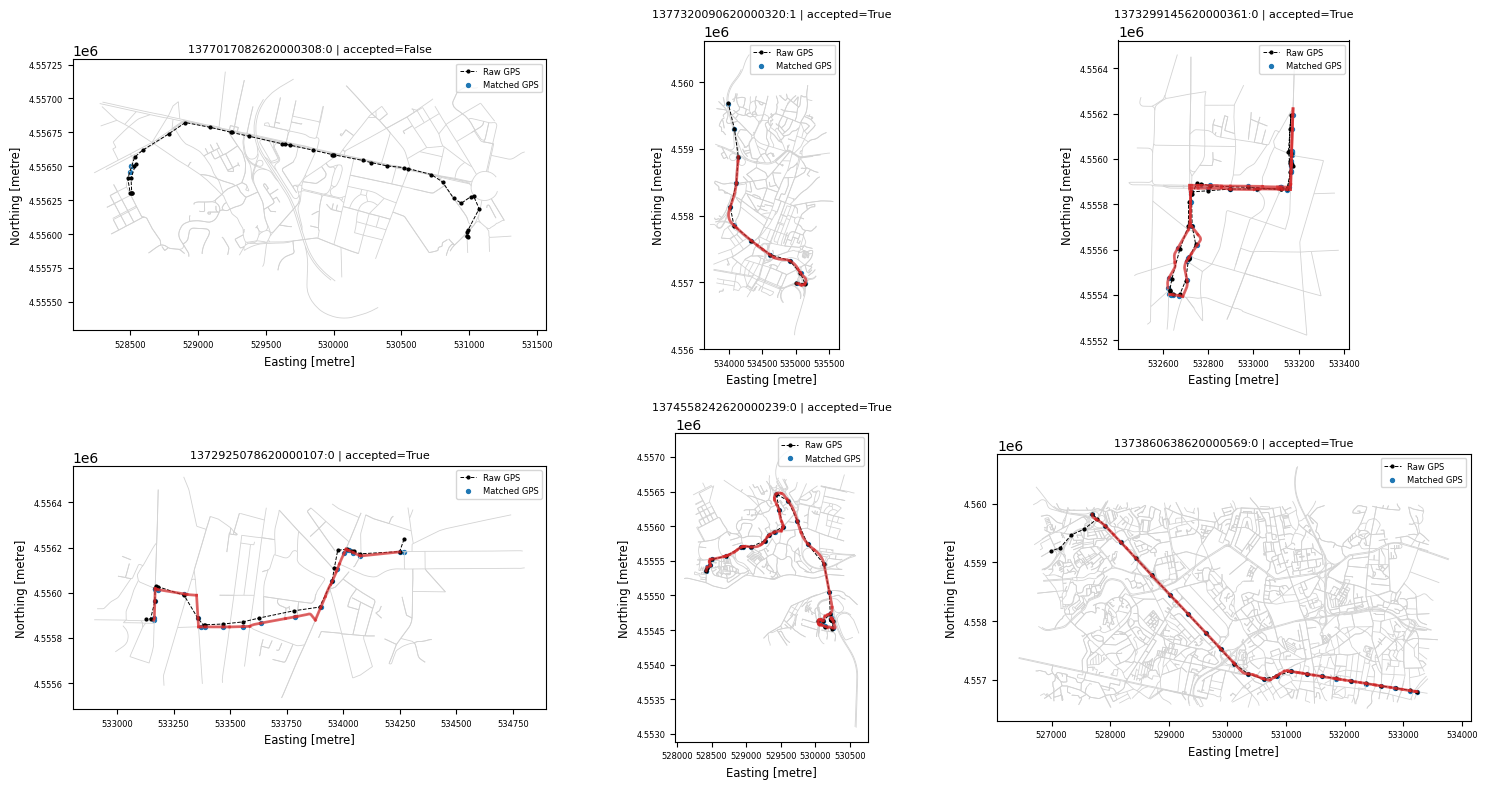

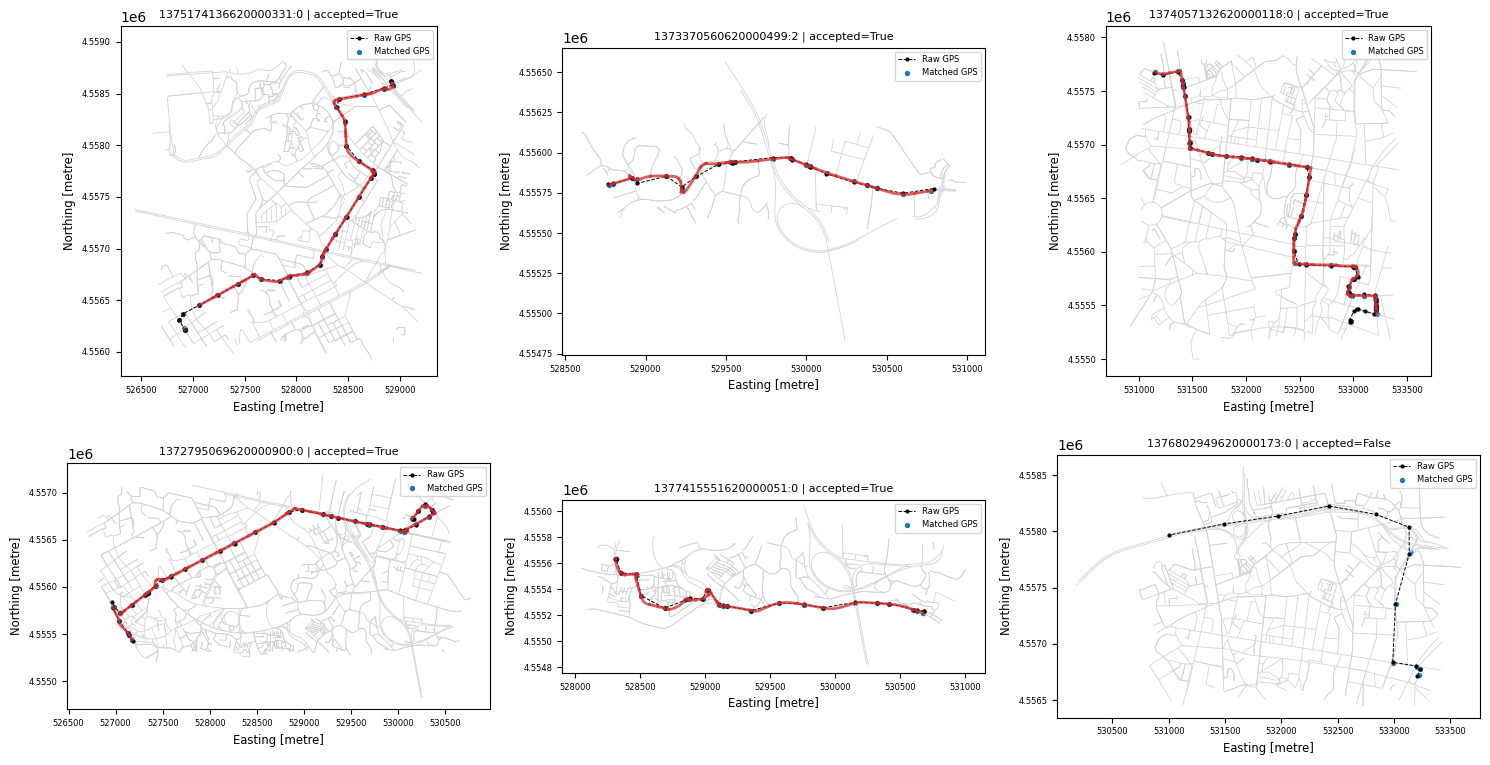

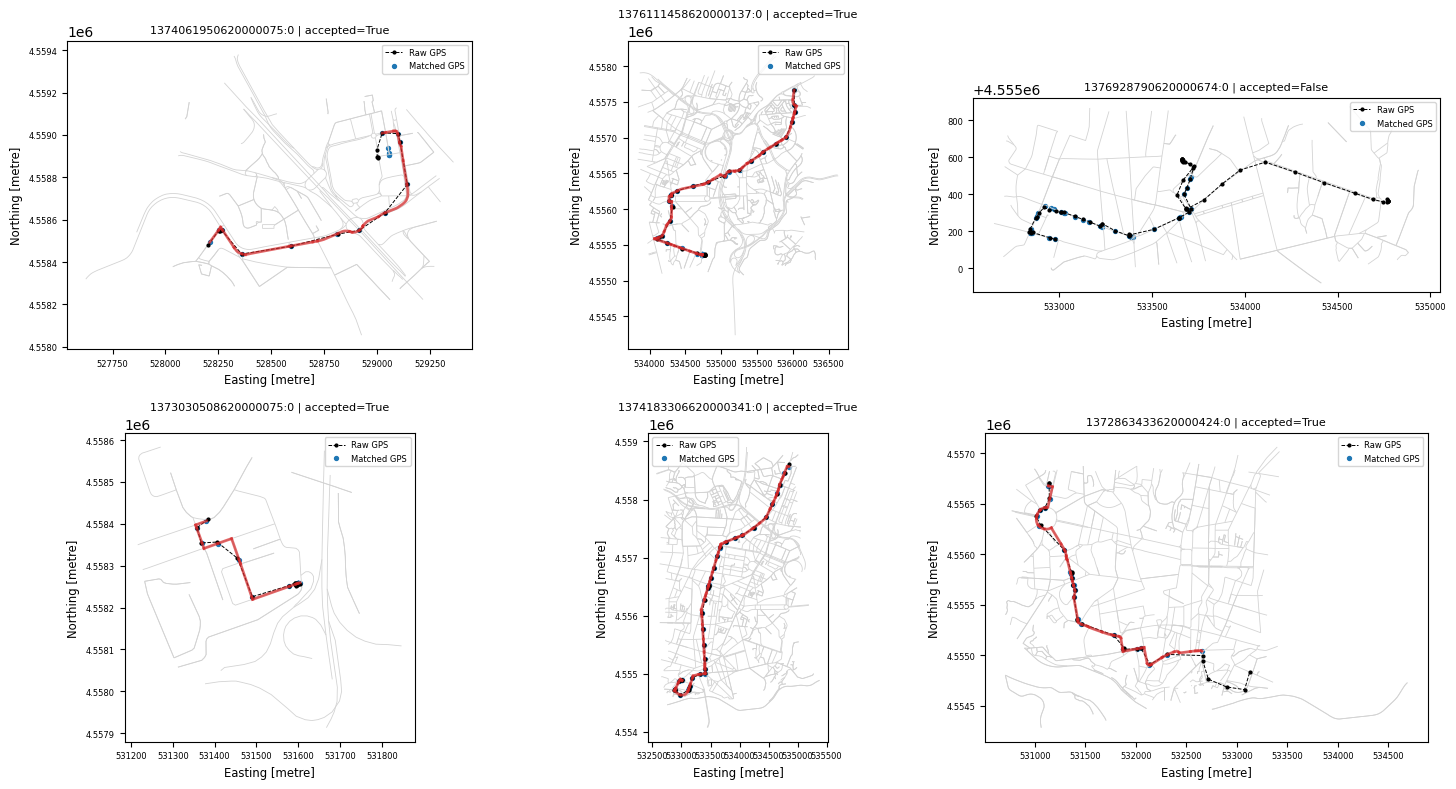

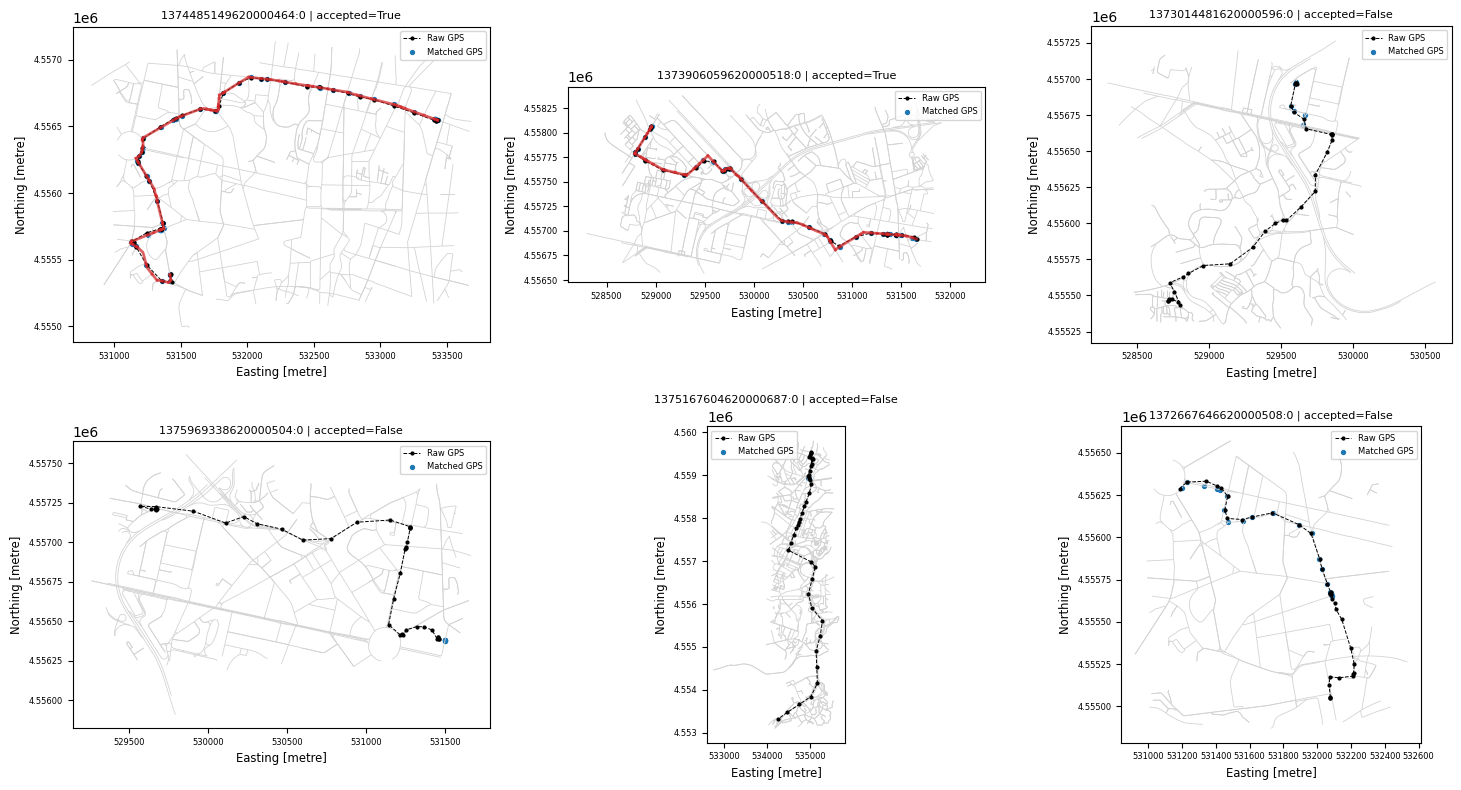

visual_qa: 22.14s; RSS 2174.7 MiB (không phải peak)


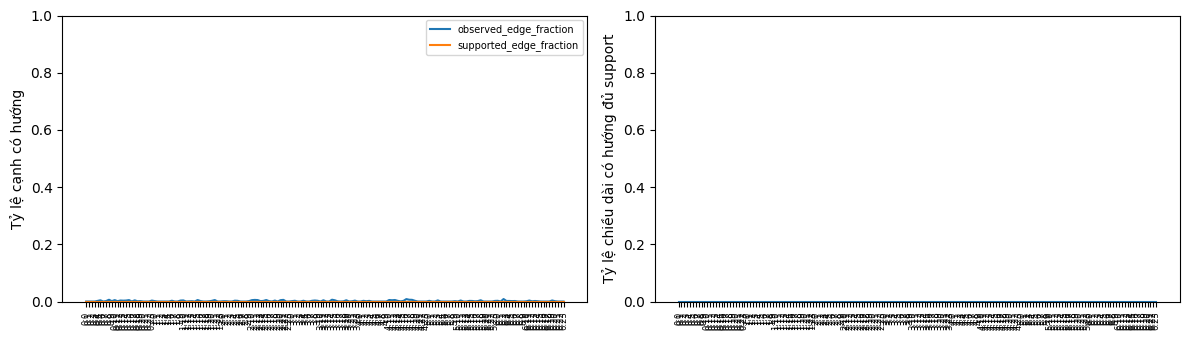

Không có cạnh đủ support để vẽ heatmap; không tô ngày/giờ thiếu dữ liệu là thông thoáng.


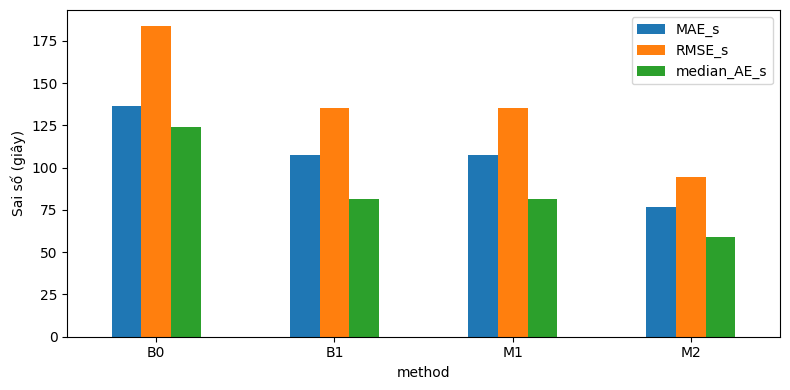

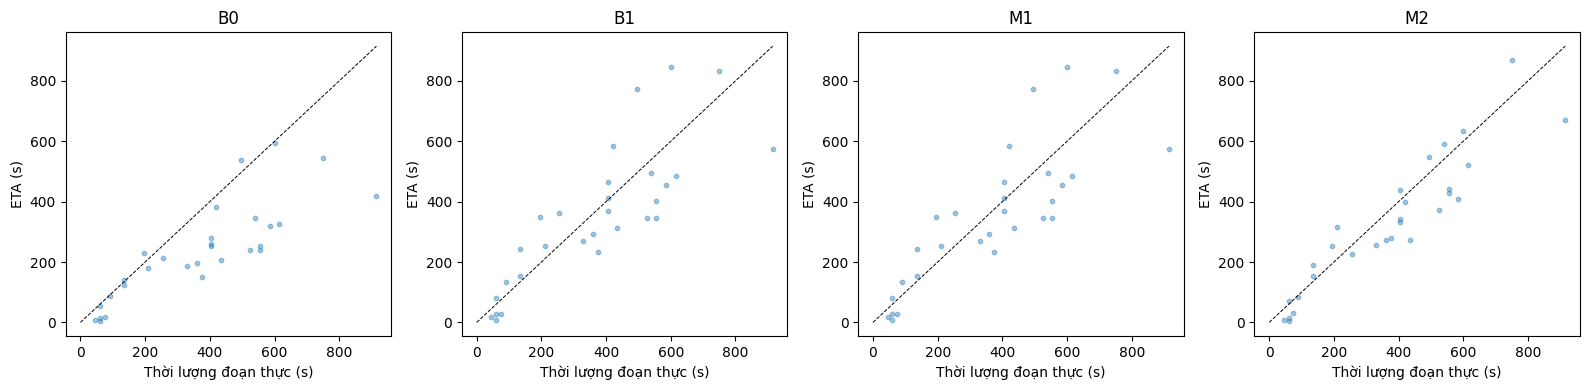

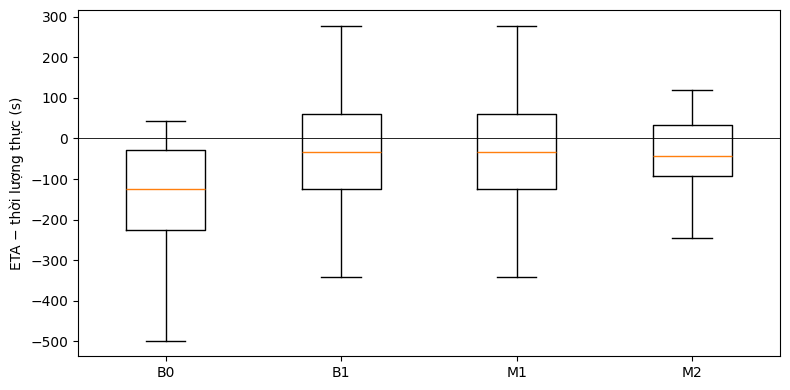

,route_id,actual_duration_s,predicted_duration_s,absolute_error_s,fine_support_fraction,case_kind
14,1376945634620000297:0:run0,405.0,413.427855,8.427855,0.0,small_relative_error
42,1377192747620000388:0:run0,540.0,496.082469,43.917531,0.0,small_relative_error
86,1377331019620000010:0:run0,405.0,368.755495,36.244505,0.0,small_relative_error
46,1377194541620000022:0:run0,60.0,6.558490,53.441510,0.0,large_relative_error
18,1376974425620000517:0:run0,195.0,349.923034,154.923034,0.0,large_relative_error
50,1377194541620000022:1:run0,135.0,241.817436,106.817436,0.0,large_relative_error


Case sai số lớn: cần xem matching_examples, coverage/fallback, đón trả khách/dừng đèn và biến động ngoài lịch sử; chưa gán nguyên nhân nhân quả.


In [18]:
if MATCH_QA is not None and not MATCH_QA.empty and PARTS_PATH is not None:
    with timed("visual_qa"):
        n_examples = min(CFG["qa_plot_trips"],len(MATCH_QA))
        example_ids = MATCH_QA.sample(n_examples,random_state=CFG["seed"]).subtrajectory_id.tolist()
        failed = MATCH_QA[~MATCH_QA.analysis_accepted]
        if len(failed) and n_examples:
            example_ids[-1] = failed.subtrajectory_id.iloc[0]
        example_ids = list(dict.fromkeys(example_ids))
        raw_examples = {}
        with PARTS_PATH.open(encoding="utf-8") as handle:
            for line in handle:
                item = json.loads(line)
                if item["subtrajectory_id"] in example_ids:
                    raw_examples[item["subtrajectory_id"]] = item
        lookup = EDGES.set_index("edge_id")
        write_json(RUN/"visual_qa_examples.json",{"subtrajectory_ids":example_ids,"manual_review_status":"not automatically certified"})
        for page in range(0,len(example_ids),6):
            fig,axes = plt.subplots(2,3,figsize=(15,8),squeeze=False)
            for ax,sub_id in zip(axes.flat,example_ids[page:page+6]):
                points = raw_examples[sub_id]["points"]
                x,y = [p["x"] for p in points],[p["y"] for p in points]
                margin = 100
                nearby = EDGES.cx[min(x)-margin:max(x)+margin,min(y)-margin:max(y)+margin]
                if not nearby.empty:
                    nearby.plot(ax=ax,color="lightgray",linewidth=.6)
                ax.plot(x,y,"o--",color="black",markersize=2,linewidth=.7,label="Raw GPS")
                if MATCHED_PARTS is not None and not MATCHED_PARTS.empty:
                    pieces = MATCHED_PARTS[MATCHED_PARTS.subtrajectory_id==sub_id]
                    for row in pieces.itertuples():
                        geometry = substring(lookup.loc[row.edge_id,"geometry"],row.entry_offset_m,row.exit_offset_m)
                        if isinstance(geometry,LineString):
                            ax.plot(*geometry.xy,color="tab:red",linewidth=2,alpha=.7)
                if MATCH_POINTS is not None and not MATCH_POINTS.empty:
                    snapped = MATCH_POINTS[MATCH_POINTS.subtrajectory_id==sub_id]
                    ax.scatter(snapped.matched_x,snapped.matched_y,color="tab:blue",s=8,label="Matched GPS")
                qa = MATCH_QA[MATCH_QA.subtrajectory_id==sub_id].iloc[0]
                ax.set_title(f"{sub_id[-22:]} | accepted={bool(qa.analysis_accepted)}",fontsize=8)
                ax.set_aspect("equal"); ax.tick_params(labelsize=6); ax.legend(fontsize=6)
            for ax in list(axes.flat)[len(example_ids[page:page+6]):]:
                ax.set_visible(False)
            save_figure(f"matching_examples_{page//6+1:02d}")

if EDGE_HISTORY is not None:
    fig,axes = plt.subplots(1,2,figsize=(12,3.5))
    cov = COVERAGE.copy()
    cov["label"] = cov.day_group+":"+(cov.slot*HISTORY["width"]).astype(str)
    for column in ["observed_edge_fraction","supported_edge_fraction"]:
        axes[0].plot(cov.label,cov[column],label=column)
    axes[0].tick_params(axis="x",rotation=90,labelsize=6); axes[0].legend(fontsize=7)
    axes[0].set(ylabel="Tỷ lệ cạnh có hướng",ylim=(0,1))
    axes[1].plot(cov.label,cov.supported_length_fraction)
    axes[1].tick_params(axis="x",rotation=90,labelsize=6)
    axes[1].set(ylabel="Tỷ lệ chiều dài có hướng đủ support",ylim=(0,1))
    save_figure("coverage")
    sufficiently_observed = EDGE_HISTORY[EDGE_HISTORY.status!="insufficient_data"]
    example_edges = sufficiently_observed.groupby("edge_id").size().sort_values(ascending=False).head(3).index
    if len(example_edges)==0:
        print("Không có cạnh đủ support để vẽ heatmap; không tô ngày/giờ thiếu dữ liệu là thông thoáng.")
    for index,edge_id in enumerate(example_edges):
        part = EDGE_HISTORY[EDGE_HISTORY.edge_id==edge_id].copy()
        part.loc[part.status=="insufficient_data",["speed_ratio","estimated_speed_kmh"]] = np.nan
        fig,axes = plt.subplots(1,2,figsize=(12,3))
        for ax,value,title in zip(axes,["estimated_speed_kmh","speed_ratio"],["Tốc độ suy ra (km/h)","Tốc độ / tham chiếu train"]):
            matrix = part.pivot(index="day_group",columns="slot",values=value)
            plot = ax.imshow(np.ma.masked_invalid(matrix.to_numpy()),aspect="auto",interpolation="nearest",cmap="viridis")
            ax.set_xticks(range(len(matrix.columns)),[str(slot*HISTORY["width"]) for slot in matrix.columns])
            ax.set_yticks(range(len(matrix.index)),matrix.index)
            ax.set(title=title,xlabel="Giờ bắt đầu slot — Europe/Lisbon")
            fig.colorbar(plot,ax=ax)
        fig.suptitle(f"Cạnh {edge_id}; tốc độ ở mức {CFG['analysis_unit']}",fontsize=10)
        save_figure(f"edge_heatmap_{index+1}")

if TEST_PREDICTIONS is not None and TEST_METRICS is not None and not TEST_METRICS.empty:
    evaluated = TEST_PREDICTIONS[TEST_PREDICTIONS.in_common_evaluation].copy()
    all_metrics = TEST_METRICS[TEST_METRICS.group=="all"].set_index("method")
    all_metrics[["MAE_s","RMSE_s","median_AE_s"]].plot.bar(figsize=(8,4),ylabel="Sai số (giây)",rot=0)
    save_figure("eta_error_comparison")
    methods = evaluated.method.unique()
    fig,axes = plt.subplots(1,len(methods),figsize=(4*len(methods),4),squeeze=False)
    for ax,method in zip(axes.flat,methods):
        part = evaluated[evaluated.method==method]
        ax.scatter(part.actual_duration_s,part.predicted_duration_s,s=10,alpha=.4)
        bound = max(part.actual_duration_s.max(),part.predicted_duration_s.max())
        ax.plot([0,bound],[0,bound],"k--",linewidth=.7)
        ax.set(title=method,xlabel="Thời lượng đoạn thực (s)",ylabel="ETA (s)")
    save_figure("observed_vs_predicted_duration")
    errors = [evaluated.loc[evaluated.method==method,"predicted_duration_s"].to_numpy()
              -evaluated.loc[evaluated.method==method,"actual_duration_s"].to_numpy() for method in methods]
    plt.figure(figsize=(8,4))
    plt.boxplot(errors,tick_labels=methods,showfliers=False)
    plt.axhline(0,color="black",linewidth=.6); plt.ylabel("ETA − thời lượng thực (s)")
    save_figure("eta_signed_errors")
    m1 = evaluated[evaluated.method=="M1"].copy()
    m1["absolute_error_s"] = (m1.predicted_duration_s-m1.actual_duration_s).abs()
    m1["relative_absolute_error"] = m1.absolute_error_s/m1.actual_duration_s
    cases = pd.concat([m1.nsmallest(3,"relative_absolute_error").assign(case_kind="small_relative_error"),
                       m1.nlargest(3,"relative_absolute_error").assign(case_kind="large_relative_error")]).drop_duplicates("route_id")
    write_table(cases,RUN/"eta_case_studies.parquet")
    display(cases[["route_id","actual_duration_s","predicted_duration_s","absolute_error_s","fine_support_fraction","case_kind"]])
    print("Case sai số lớn: cần xem matching_examples, coverage/fallback, đón trả khách/dừng đèn và biến động ngoài lịch sử; chưa gán nguyên nhân nhân quả.")

## 12. Kiểm thử kỹ thuật tự động (fixture, không phải benchmark)

Kiểm thử kiểm tra timestamp không bị nén sau lọc; out-of-region/re-entry; split chuyến
đầy đủ; partial offset; các lần quay lại cạnh; chia thời gian qua giờ/nửa đêm/DST;
HMM theo topology; support không đếm mảnh; fallback; feature không dùng target; ETA
đổi profile khi đồng hồ dự đoán qua giờ; các hàm mining/ETA/M2 trên fixture xác định.
Chỉ xuất pass/fail kỹ thuật, không xuất số đo ETA giả thành kết quả thực nghiệm.

In [19]:
def run_technical_tests():
    results = []
    def check(name,condition):
        if not condition:
            raise AssertionError(name)
        results.append({"test":name,"status":"passed","scope":"synthetic fixture only"})
    west,south,east,north = CFG["bbox"]
    lon,lat = (west+east)/2,(south+north)/2
    base_time = int(BOUNDS[0].timestamp())+3600
    points = [[lon+i*.00001,lat] for i in range(12)]
    points[5] = [east+1,north+1]
    cleaned,audit = clean_polyline(json.dumps(points),base_time)
    indices = [p["original_index"] for part in cleaned for p in part]
    check("timestamp_original_index_after_region_filter",all(p["timestamp"]==base_time+15*p["original_index"] for part in cleaned for p in part))
    check("region_reentry_creates_gap",len(cleaned)==2 and 5 not in indices and cleaned[1][0]["original_index"]==6)
    points[5] = [None,lat]
    cleaned,_ = clean_polyline(json.dumps(points),base_time)
    check("invalid_coordinate_creates_gap",len(cleaned)==2 and cleaned[1][0]["timestamp"]==base_time+90)
    jumping = [[lon+i*.00001,lat] for i in range(14)]
    jumping[6] = [lon+.04,lat]
    jump_parts,jump_audit = clean_polyline(json.dumps(jumping),base_time)
    check("gps_jump_splits_original_time",jump_audit["jump_boundaries"]>=1 and all(
          b["original_index"]==a["original_index"]+1 for part in jump_parts for a,b in zip(part[:-1],part[1:])))
    check("whole_trip_crossing_train_boundary_dropped",assign_split(BOUNDS[1]-pd.Timedelta(seconds=20),BOUNDS[1]+pd.Timedelta(seconds=10))=="boundary_or_outside")
    check("boundary_touch_dropped",assign_split(BOUNDS[1]-pd.Timedelta(seconds=30),BOUNDS[1])=="boundary_or_outside")
    check("validation_start_inclusive",assign_split(BOUNDS[1],BOUNDS[1]+pd.Timedelta(seconds=30))=="validation")
    allocation = interval_pieces([("a",20,40),("b",0,10)],15)
    check("partial_edge_distance_and_duration",sum(r[3] for r in allocation)==30 and abs(sum(r[4] for r in allocation)-15)<1e-10 and allocation[0][4]==10)
    still = interval_pieces([("a",30,30)],15)
    check("stationary_time_retained",still[0][3]==0 and still[0][4]==15)
    start = pd.Timestamp("2013-07-01 23:59:45",tz="Europe/Lisbon")
    fragments = list(hourly_fragments(start,start+pd.Timedelta(seconds=30),120))
    check("hour_midnight_conservation",len(fragments)==2 and fragments[0]["date"]!=fragments[1]["date"]
          and sum(f["duration_s"] for f in fragments)==30 and sum(f["distance_traversed_m"] for f in fragments)==120)
    start = pd.Timestamp("2013-10-27T00:59:45Z")
    fragments = list(hourly_fragments(start,start+pd.Timedelta(seconds=30),60))
    check("dst_utc_differences",sum(f["duration_s"] for f in fragments)==30 and len(fragments)==2 and all(f["hour"]==1 for f in fragments))
    fake_predictor = lambda unit,at: {"seconds_per_m":1.0 if utc(at).hour==8 else 2.0,
                                    "sufficient":True,"source":"fine"}
    eta = predict_eta([{"unit_id":"toy","distance_m":100}],pd.Timestamp("2013-07-01T08:59:30Z"),None,"M1",predictor=fake_predictor)
    check("eta_predicted_clock_crosses_hours",abs(eta["predicted_duration_s"]-170)<1e-6)
    fixture_edges = gpd.GeoDataFrame([
        {"edge_id":"a","u":1,"v":2,"key":0,"fmm_id":1,"geometry":LineString([(0,0),(100,0)]),"length_m":100.,"road_class":"residential","in_study":True,"x":50.,"y":0.},
        {"edge_id":"b","u":2,"v":3,"key":0,"fmm_id":2,"geometry":LineString([(100,0),(200,0)]),"length_m":100.,"road_class":"residential","in_study":True,"x":150.,"y":0.},
        {"edge_id":"parallel","u":1,"v":2,"key":1,"fmm_id":3,"geometry":LineString([(0,0),(50,30),(100,0)]),"length_m":2*np.hypot(50,30),"road_class":"primary","in_study":True,"x":50.,"y":15.},
    ],crs=CFG["metric_crs"])
    fixture_points = [{"original_index":i,"timestamp":base_time+15*i,"x":x,"y":1.0} for i,x in enumerate([20,40,65,90,120,150,180])]
    backend_checks = []
    if importlib.util.find_spec("leuvenmapmatching") is not None and importlib.util.find_spec("rtree") is not None:
        backend_checks.append(LeuvenAdapter(fixture_edges,CACHE/"technical_fixture_ubodt"))
    if importlib.util.find_spec("fastmm") is not None:
        backend_checks.append(FastMMAdapter(fixture_edges,CACHE/"technical_fixture_ubodt"))
    results.append({"test":"sequence_matcher_availability","status":"passed" if backend_checks else "skipped_no_matcher",
                    "scope":"synthetic fixture only"})
    for engine in backend_checks:
        intervals,snapped = engine.match(fixture_points)
        check(engine.name+"_directed_sequence_and_partial_offsets",len(intervals)>=4 and bool(snapped)
              and all(p[0] in ["a","b"] for interval in intervals for p in interval["parts"])
              and abs(intervals[0]["parts"][0][1]-20)<2)
        sub = {"trip_id":"fixture","taxi_id":"fixture_taxi","subtrajectory_id":"fixture:0","split":"train","points":fixture_points}
        rows,qa,_,_ = match_subtrajectory(sub,engine,{row.edge_id:row for row in fixture_edges.itertuples()})
        check(engine.name+"_qa_and_apportioning",qa["analysis_accepted"] and abs(sum(r["duration_s"] for r in rows)-90)<1e-5)
    traversal_rows = []
    for index,edge_id in enumerate(["a","a","b","a"]):
        begin = BOUNDS[0]+pd.Timedelta(seconds=15*index)
        traversal_rows.append({"route_id":"revisit","trip_id":"fixture","taxi_id":"fixture_taxi",
            "subtrajectory_id":"fixture:0","split":"train","unit_id":edge_id,"edge_id":edge_id,
            "entry_time":begin,"exit_time":begin+pd.Timedelta(seconds=15),"part_index":0,
            "entry_offset_m":20. if index==1 else 0.,"exit_offset_m":40. if index==1 else 20.,
            "distance_traversed_m":20.,"duration_s":15.,"match_quality":.95,"is_interpolated":False,
            "gps_road_error_m":1.,"interval_id":f"fixture_interval_{index}"})
    revisit = build_traversals(pd.DataFrame(traversal_rows))
    check("revisiting_same_edge_has_distinct_traversal",len(revisit)==3 and revisit[revisit.edge_id=="a"].traversal_id.nunique()==2)
    corridor_edges = assign_corridors(fixture_edges)
    check("corridor_respects_road_class_and_direction",corridor_edges.set_index("edge_id").loc["a","unit_id"]!=corridor_edges.set_index("edge_id").loc["parallel","unit_id"])
    toy_rows = []
    for trip in range(30):
        date = BOUNDS[0].tz_convert("Europe/Lisbon").normalize()+pd.Timedelta(days=trip%5)
        for hour in [7,8,9,14]:
            for unit in ["a","b"]:
                toy_rows.append({"trip_id":f"toy{trip}","taxi_id":f"taxi{trip%8}","split":"train","unit_id":unit,
                    "date":str(date.date()),"weekday":date.weekday(),"hour":hour,"distance_m":100.,
                    "duration_s":20.+(hour==8)*10+trip%3,"match_quality":.95,
                    "interval_ids":[f"toy{trip}:{hour}"]})
    toy_hourly = pd.DataFrame(toy_rows)
    toy_meta = pd.DataFrame({"unit_id":["a","b"],"road_class":["residential"]*2,"length_m":[100.]*2,"x":[50.,150.],"y":[0.,0.],"in_study":[True,True]})
    history = fit_history(toy_hourly,toy_meta,2,"weekday_weekend")
    check("history_support_counts_trips_not_fragments",history["tables"]["unit"].n_trips.max()==30)
    heldout_rejected = False
    try:
        fit_history(toy_hourly.assign(split="test"),toy_meta,2,"weekday_weekend")
    except ValueError:
        heldout_rejected = True
    check("history_rejects_heldout_input",heldout_rejected)
    query_time = BOUNDS[0]+pd.Timedelta(hours=8)
    check("fallback_for_unseen_unit",lookup_prediction(history,"M1","unseen",query_time)["source"]=="global")
    daily,historical = mining_tables(toy_hourly,history,.4)
    check("recurrence_denominator_only_supported_days",(historical.eligible_days<=historical.n_days).all()
          and (daily.status!="insufficient_data").any())
    edge_fixture = fixture_edges[fixture_edges.edge_id.isin(["a","b"])].copy()
    edge_fixture["unit_id"] = edge_fixture.edge_id
    daily_layer,history_layer = edge_layers(toy_hourly,daily,historical,edge_fixture,history)
    check("historical_full_grid_keeps_missing_separate",len(history_layer)==2*2*12
          and (history_layer.status=="insufficient_data").any())
    check("edge_recurrence_uses_edge_eligible_days",history_layer.eligible_days.le(history_layer.edge_n_days.fillna(0)).all())
    cluster_input = daily_layer.copy()
    cluster_input["status"] = "slowdown"
    cluster_input["speed_ratio"] = .3
    clusters = slow_clusters(cluster_input,edge_fixture,["date","slot"])
    check("slow_clusters_use_topology",not clusters.empty and clusters.n_edges.eq(2).all())
    features = m2_features(["a"],[query_time],toy_meta)
    check("m2_features_exclude_observed_targets_and_raw_ids",not set(features)&{"duration_s","speed_kmh","seconds_per_m","edge_id","unit_id","taxi_id"})
    toy_model = fit_m2(toy_hourly,toy_meta,{"max_iter":5,"max_leaf_nodes":7,"l2_regularization":2})
    check("m2_train_and_inference_cpu",np.isfinite(predict_eta([{"unit_id":"a","distance_m":80}],query_time,history,"M2",toy_model)["predicted_duration_s"]))
    consistency,common = split_taxi_consistency(toy_hourly,history,[.3,.4,.5])
    check("split_taxi_consistency_executes",len(consistency)==3 and not common.empty)
    route_fixture = pd.DataFrame([{"route_id":"fixture_route","trip_id":"fixture_test","taxi_id":"heldout_taxi","split":"test",
        "departure_time":query_time,"actual_duration_s":40.,"distance_m":180.,
        "path":[{"unit_id":"a","edge_id":"a","distance_m":80.},{"unit_id":"b","edge_id":"b","distance_m":100.}]}])
    prediction = evaluate_routes(route_fixture,history,["B0","B1","M1","M2"],toy_model)
    check("four_methods_same_observed_route",len(prediction)==4 and prediction.predicted_duration_s.notna().all())
    metrics = eta_metrics(prediction.assign(evaluation_group="fixture_only"))
    check("eta_metrics_all_four_methods",len(metrics)==4 and metrics.MAE_s.ge(0).all())
    cache_a,cache_b = stable_hash(["graphA",CFG["candidate_radius_m"]]),stable_hash(["graphB",CFG["candidate_radius_m"]])
    check("cache_identity_changes_with_graph",cache_a!=cache_b)
    return pd.DataFrame(results)

TECHNICAL_TEST_RESULTS = None
if CFG["run_technical_tests"]:
    with timed("technical_tests_not_experiment"):
        TECHNICAL_TEST_RESULTS = run_technical_tests()
        write_table(TECHNICAL_TEST_RESULTS,RUN/"technical_tests.parquet")
        display(TECHNICAL_TEST_RESULTS)
        passed = int(TECHNICAL_TEST_RESULTS.status.eq("passed").sum())
        skipped = len(TECHNICAL_TEST_RESULTS)-passed
        record_stage("technical_tests","complete",f"{passed} passed, {skipped} skipped; fixture, không phải benchmark Porto.")

,test,status,scope
0,timestamp_original_index_after_region_filter,passed,synthetic fixture only
1,region_reentry_creates_gap,passed,synthetic fixture only
2,invalid_coordinate_creates_gap,passed,synthetic fixture only
3,gps_jump_splits_original_time,passed,synthetic fixture only
4,whole_trip_crossing_train_boundary_dropped,passed,synthetic fixture only
5,boundary_touch_dropped,passed,synthetic fixture only
6,validation_start_inclusive,passed,synthetic fixture only
7,partial_edge_distance_and_duration,passed,synthetic fixture only
8,stationary_time_retained,passed,synthetic fixture only
9,hour_midnight_conservation,passed,synthetic fixture only


[technical_tests] complete: 30 passed, 0 skipped; fixture, không phải benchmark Porto.
technical_tests_not_experiment: 1.64s; RSS 2075.7 MiB (không phải peak)


## 13. Kết quả lưu 



In [20]:
with timed("final_manifest"):
    if TRIP_AUDIT is not None:
        counts = []
        for split in ["train","validation","test","boundary_or_outside"]:
            original = TRIP_AUDIT[TRIP_AUDIT.split==split]
            matched_ids = set(MATCH_QA.loc[MATCH_QA.analysis_accepted & MATCH_QA.split.eq(split),"trip_id"]) if MATCH_QA is not None and not MATCH_QA.empty else set()
            counts.append({"split":split,"sampled_trips":len(original),"after_cleaning":int(original.n_subtrajectories.gt(0).sum()),
                           "after_quality_matching":len(matched_ids),
                           "eta_eligible_trips":int(ROUTES.loc[ROUTES.split.eq(split),"trip_id"].nunique()) if ROUTES is not None and not ROUTES.empty else 0})
        write_table(pd.DataFrame(counts),RUN/"filter_counts_by_split.parquet")
        display(pd.DataFrame(counts))
    manifest = {"run_key":RUN_KEY,"mode":CFG["mode"],"config":CFG,"code_hash":CODE_HASH,
        "graph_hash":GRAPH_HASH,"data_key":DATA_KEY,"versions":VERSIONS,"stages":STAGES,
        "artifacts":[str(path.relative_to(RUN)) for path in RUN.rglob("*") if path.is_file()],
        "finished_utc":datetime.now(timezone.utc).isoformat(),
        "experiment_claim":"Real GPS evaluation only when evaluation stage is complete; smoke is technical only.",
        "technical_fixture_is_not_porto":True}
    write_json(RUN/"manifest.json",manifest)
    write_json(OUTPUT/"latest_run.json",{"run_key":RUN_KEY,"folder":str(RUN),"stages":STAGES})
display(pd.DataFrame(STAGES).T)
print("Thư mục kết quả:",RUN)
if STAGES.get("evaluation",{}).get("status")!="complete":
    print("Chưa có benchmark Porto được xác minh. Xem stage_status.json để biết phần bị chặn.")

,split,sampled_trips,after_cleaning,after_quality_matching,eta_eligible_trips
0,train,194,189,126,126
1,validation,71,69,39,39
2,test,35,34,25,25
3,boundary_or_outside,0,0,0,0


final_manifest: 0.08s; RSS 2075.0 MiB (không phải peak)

,status,detail
data,complete,300 chuyến trong mẫu; xem trip_audit.
graph,complete,23732 cạnh; graph_hash=862367c3d1f7fde1
matching,complete,12383 partial-edge pieces; leuven_hmm.
observations,complete,6485 traversals; max conservation error 1.78e-...
models,complete,Chọn weekday_1h bằng validation; M2=enabled.
mining,complete,Ngưỡng 0.4; cấu hình đã chốt trước đánh giá test.
evaluation,complete,"29 routes chung, 25/35 selected test trips."
technical_tests,complete,"30 passed, 0 skipped; fixture, không phải benc..."


Thư mục kết quả: D:\Học tập\Tài liệu\1_2026-2027\CS313\Tracejoy_DataMining\outputs\bdd8bc9d5a3d7c4c_20261021T142049385930Z


## Tài liệu tham khảo

Tài liệu thực sự có trong workspace và đã dùng:

1. Yu Zheng (2015), *Trajectory Data Mining: An Overview*, bản PDF `Trajectory Data Mining An Overview.pdf`,
   41 trang. Tham chiếu §3.1, §3.4–3.5, §5, §6.4, §8.2, §9.1;
   [DOI 10.1145/2743025](https://doi.org/10.1145/2743025).
2. *Trajectory_Data_Mining_Porto.pdf*, 12 trang, đề cương ngày 14/10/2026.
   Dùng khung preprocessing → matching → speed/event mining → evaluation;
   thay đổi kỹ thuật được giải thích đầu notebook.

Dataset và bản đồ:

3. [Kaggle — ECML/PKDD 15 Taxi Trajectory Prediction (I), Data](https://www.kaggle.com/competitions/pkdd-15-predict-taxi-service-trajectory-i/data).
   Dùng `train.csv` hoàn chỉnh; không dùng competition test làm nhãn ùn tắc.
4. [UCI — Taxi Service Trajectory Prediction Challenge, id 339](https://archive.ics.uci.edu/dataset/339/taxi+service+trajectory+prediction+challenge+ecml+pkdd+2015),
   đối chiếu schema, thời gian mẫu và cảnh báo DAYTYPE.
5. [© OpenStreetMap contributors](https://www.openstreetmap.org/copyright), nguồn road graph hiện tại.

API chính thức dùng để triển khai (phiên bản cài thực tế lưu trong `environment.json`):

- [OSMnx user reference](https://osmnx.readthedocs.io/en/stable/user-reference.html):
  graph_from_polygon, project_graph, save/load_graphml.
- [fastmm official repository](https://github.com/kodonnell/fastmm) và
  [API stubs](https://github.com/kodonnell/fastmm/blob/main/python/fastmm/fastmm.pyi):
  backend ưu tiên, chưa chạy trong môi trường Python 3.13 này vì thiếu wheel tương thích.
- [Leuven MapMatching BaseMatcher](https://leuvenmapmatching.readthedocs.io/en/latest/classes/matcher/BaseMatcher.html),
  [DistanceMatcher source](https://leuvenmapmatching.readthedocs.io/en/latest/_modules/leuvenmapmatching/matcher/distance.html),
  [official repository](https://github.com/wannesm/LeuvenMapMatching): backend HMM fallback thực tế.
- [pandas](https://pandas.pydata.org/docs/): CSV chunks, thời gian timezone-aware, groupby, Parquet.
- [NumPy](https://numpy.org/doc/stable/): phép tính số và thống kê.
- [PyArrow](https://arrow.apache.org/docs/python/): lưu Parquet.
- [GeoPandas](https://geopandas.org/en/stable/docs.html), [Shapely](https://shapely.readthedocs.io/en/stable/manual.html),
  [pyproj](https://pyproj4.github.io/pyproj/stable/): CRS, hình học, offset mét, GeoParquet.
- [NetworkX](https://networkx.org/documentation/stable/reference/algorithms/component.html):
  topology và weakly_connected_components.
- [scikit-learn HGBRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html),
  [ColumnTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html):
  M2, preprocessing train-only; [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html).
- [Matplotlib](https://matplotlib.org/stable/), [IPython display](https://ipython.readthedocs.io/en/stable/api/generated/IPython.display.html): hình và hiển thị notebook.
- [psutil](https://psutil.readthedocs.io/), [joblib](https://joblib.readthedocs.io/en/stable/),
  [threadpoolctl](https://github.com/joblib/threadpoolctl), [Rtree](https://rtree.readthedocs.io/):
  bộ nhớ RSS, lưu model, giới hạn CPU, spatial index cho Leuven.
- [Python standard library](https://docs.python.org/3/library/): sqlite3, zipfile, hashlib,
  pathlib, json, contextlib; [tzdata](https://tzdata.readthedocs.io/) cung cấp timezone khi cần.

PDF được đọc khi soạn notebook bằng [pypdf](https://pypdf.readthedocs.io/); notebook chạy
pipeline không cần pypdf. Notebook tạo/kiểm tra bằng [nbformat](https://nbformat.readthedocs.io/)
và [nbclient](https://nbclient.readthedocs.io/). Không dùng Streamlit, Folium, deep learning
hay nhãn congestion bên ngoài trong giai đoạn này.